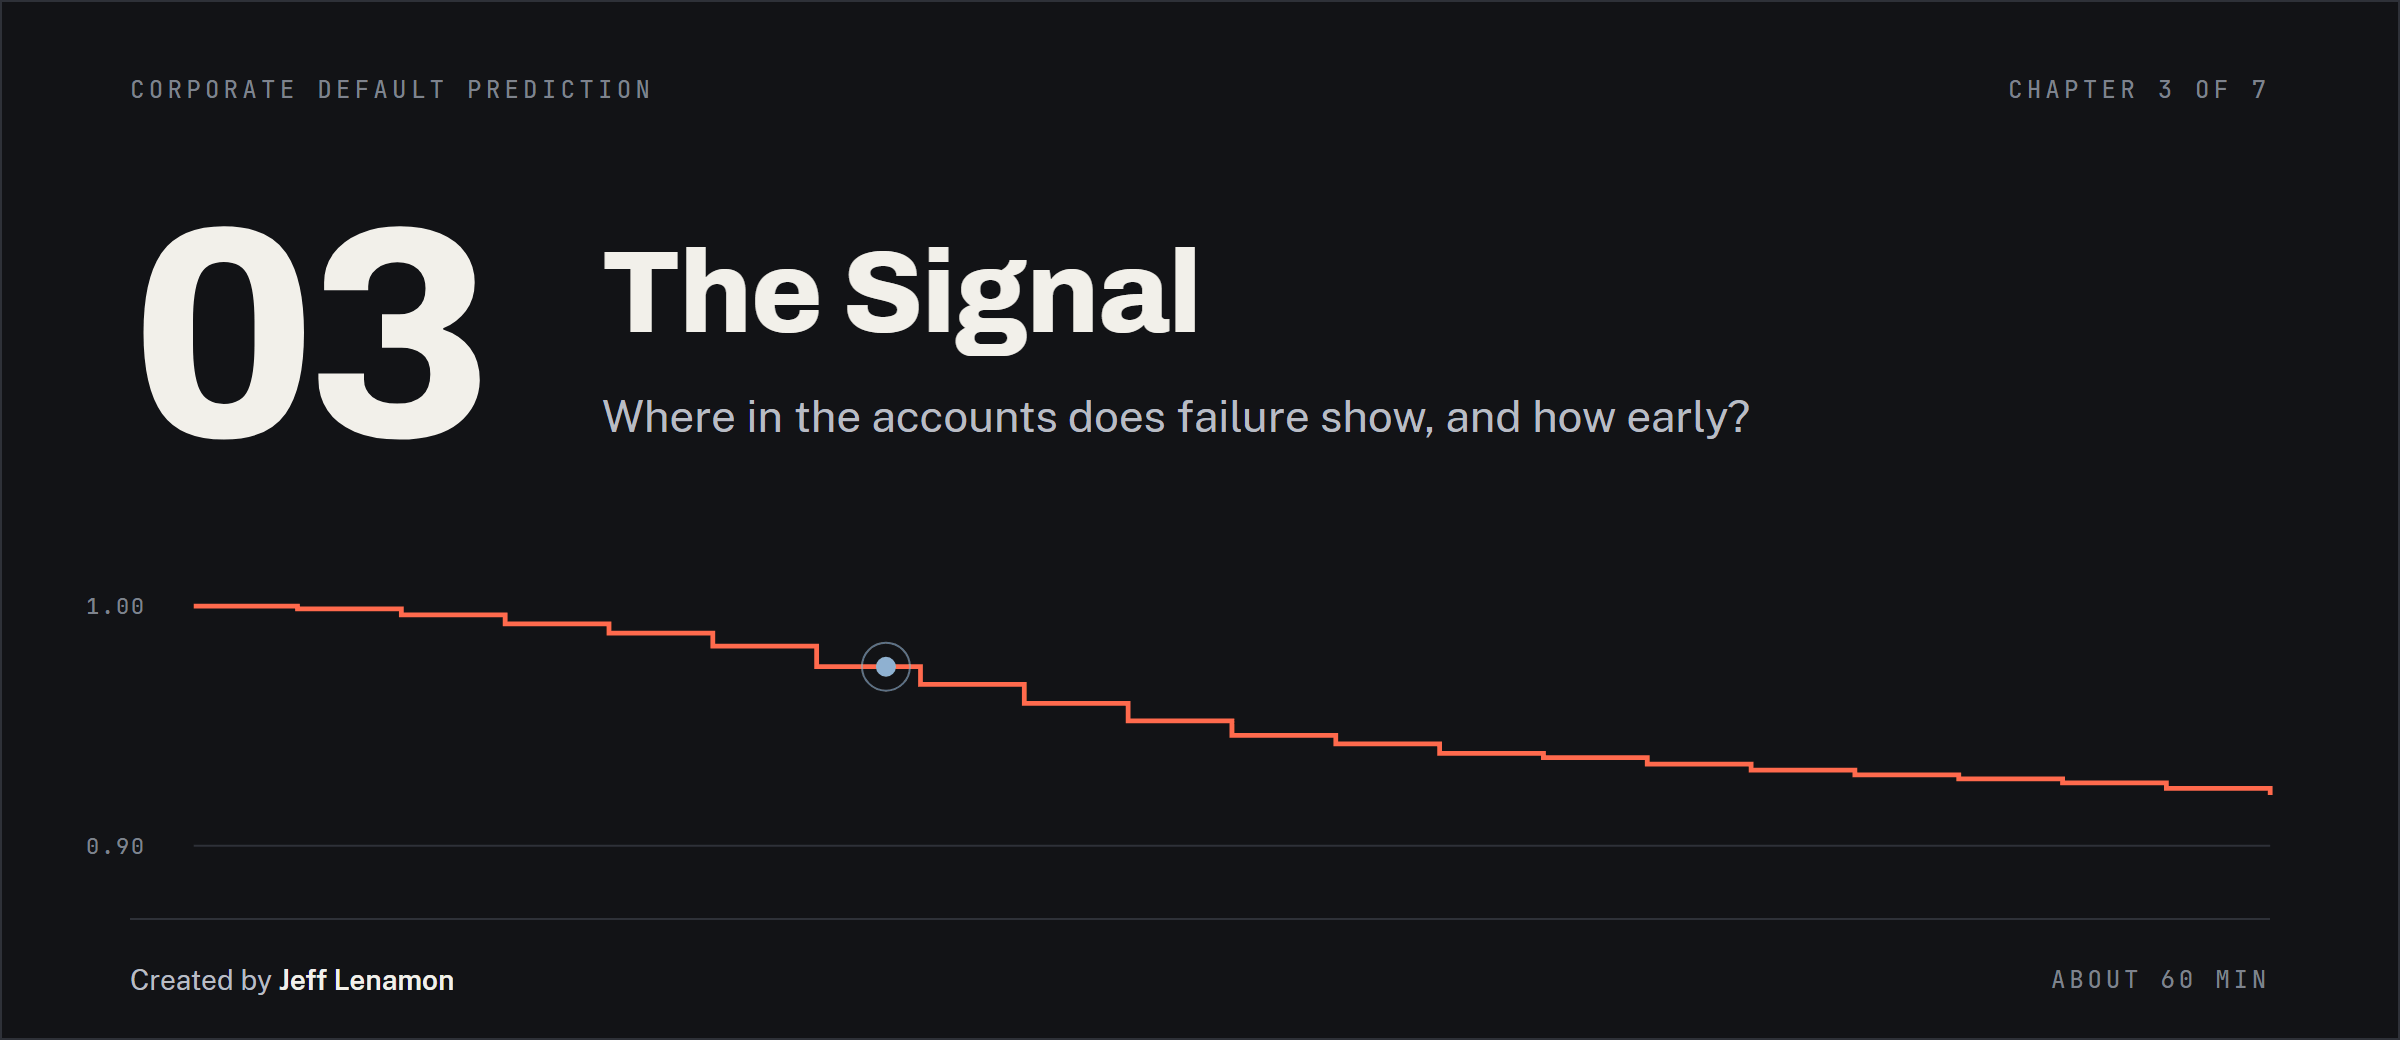

# Chapter 3: The Signal

Where a coming failure shows in a company's accounts, how early it shows, and how the accounts themselves shift over the years.

> This casebook is educational content created in a personal capacity

> Nothing here is investment advice or a recommendation to buy or sell any security

> The data is a public research dataset with anonymized company names

## The Question

Chapter 2 put a date on each failure and a label on each firm-year.
The accounts are still raw: 17 accounting items a year.

A lender reads ratios, and reads them over several years.
Where in the accounts does failure show, and how early?

## What You Will Learn

By the end you can:

- turn the accounting items into ratios, family by family;
- follow failed companies through the years before their last filing;
- read the failure rate along a ratio, with an honest interval on it;
- explain why the largest losses are not the riskiest accounts;
- measure how far the ratios drift from one era to the next.

## What You Need

Chapter 2, which wrote the labeled panel this chapter reads.
The data file is read again for the last filings of failed companies, which the label leaves out.

The chapter writes one table, `features`, that every later chapter reads.

## Your Route

![Your route through Chapter 3: 1 Setting Up, 6 minutes; 2 From Amounts to Ratios, 4 minutes; 3 Looking at Skewed Ratios, 3 minutes; 4 Anatomy of a Failure, 4 minutes; 5 Failure Rate Along Each Ratio, 6 minutes; 6 Why the Worst-Looking Companies Are Not the Riskiest, 4 minutes; 7 Ranking the Signals One at a Time, 3 minutes; 8 Ratios That Repeat, 3 minutes; 9 The Risk Map, 3 minutes; 10 What Changed Since Last Year, 5 minutes; 11 The Ground Is Moving, 8 minutes.](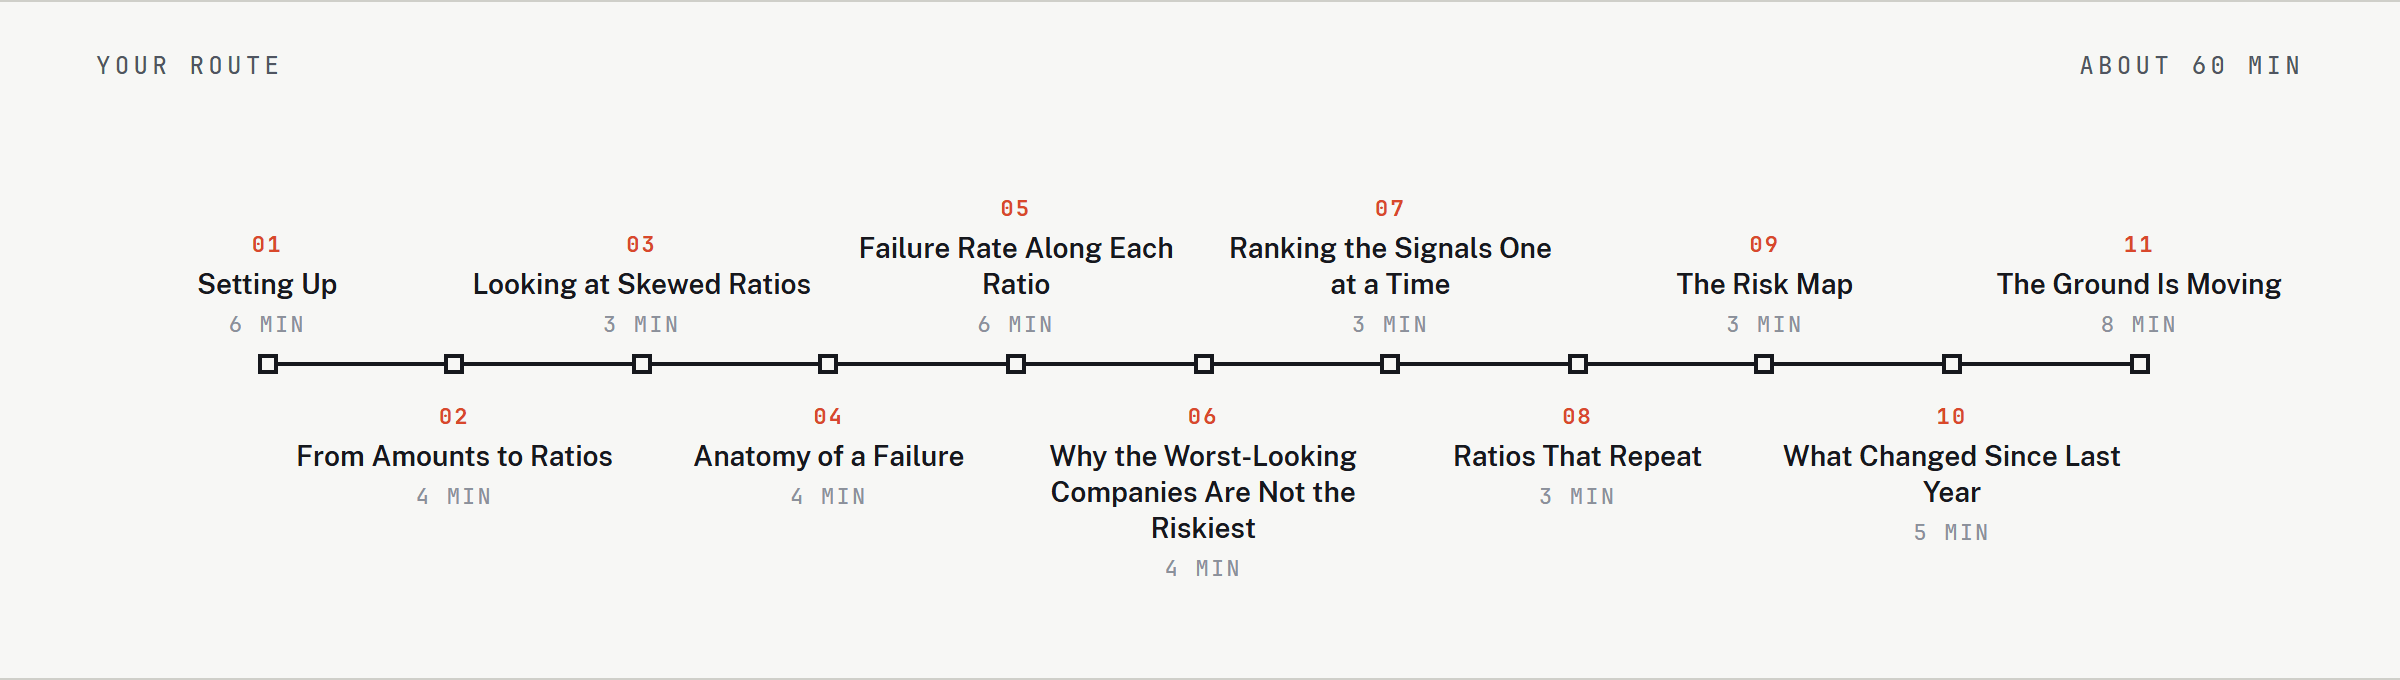)

**Time.** About 52 minutes to read and run, then about 9 for Your Turn.

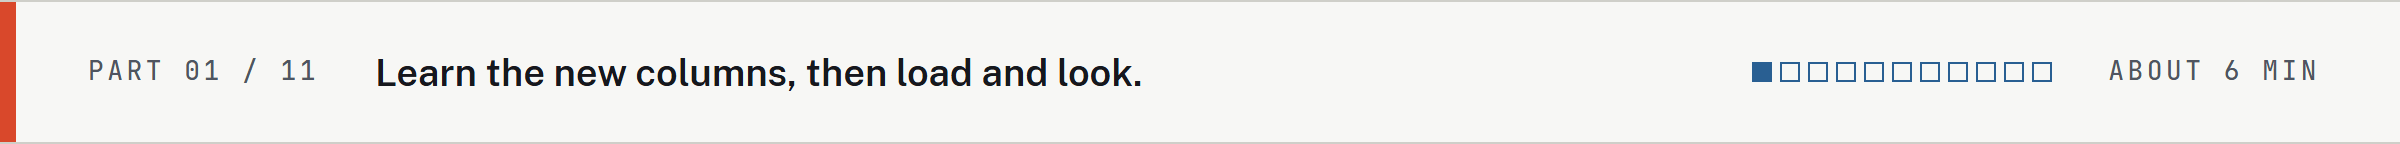

# Setting Up

Make sure the Jupyter kernel `corp-default` is selected before you run a cell.
If it is not in the list, or an import fails, the [Quick Start](../README.md#quick-start) shows how to register it and refresh the list.

## The Data Dictionary

The chapter reads the labeled panel of Chapter 2.
Its outcome columns, `target`, `failed`, `last_year`, and `years_to_final`, are described there, and none of them is ever an input to a model.

From the accounting items the chapter builds 24 **ratios**, in 7 families.

| Family | Column | What it is |
| --- | --- | --- |
| Leverage | `liabilities_to_assets` | Total liabilities over total assets |
| | `lt_debt_to_assets` | Long-term debt over total assets |
| | `book_equity_to_assets` | Total assets less total liabilities, over total assets |
| | `debt_to_ebitda` | Long-term debt over EBITDA, blank unless EBITDA is positive |
| | `no_lt_debt` | 1 when long-term debt is zero |
| Profitability | `roa` | Net income over total assets, the **return on assets** |
| | `ebit_to_assets` | EBIT over total assets |
| | `ebitda_to_assets` | EBITDA over total assets |
| | `net_margin` | Net income over net sales |
| | `ebitda_margin` | EBITDA over net sales |
| | `gross_margin` | Gross profit over net sales |
| | `negative_ebitda` | 1 when EBITDA is zero or below |
| | `retained_earnings_to_assets` | Retained earnings over total assets |
| Liquidity | `current_ratio` | Current assets over current liabilities |
| | `quick_ratio` | Current assets less inventory, over current liabilities |
| | `working_capital_to_assets` | Current assets less current liabilities, over total assets |
| | `current_assets_to_assets` | Current assets over total assets |
| | `current_liabilities_to_liabilities` | Current liabilities over total liabilities |
| Coverage | `ffo_to_liabilities` | Funds from operations (FFO), net income plus depreciation and amortization, over total liabilities |
| Activity | `asset_turnover` | Net sales over total assets |
| Market | `mve_to_liabilities` | Market value of equity over total liabilities |
| | `market_to_book_assets` | Market value of equity plus total liabilities, over total assets |
| Size | `log_assets` | The logarithm of total assets |
| | `log_market_cap` | The logarithm of the market value of equity |

It then adds **history**: what changed since one year earlier and since two.

| Column | What it is |
| --- | --- |
| `d1_`, `d2_`, then a ratio | The change in that ratio over one year, or over two |
| `g1_`, `g2_`, then an item | The growth of sales, assets, or market value over one year or two, in logarithms |
| `loss_1y_ago`, `loss_2y_ago` | 1 when net income was negative one year ago, or two |
| `years_observed` | How many years the company has filed so far |

The industry codes of Chapter 1, `division` and `major_group`, are joined on at the end.

Q. What gets imported and loaded?

In [1]:
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, PercentFormatter
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import gaussian_kde, ks_2samp, rankdata
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict

from corp_default import store, viz
from corp_default.classic import altman_z
from corp_default.data import RAW_ITEMS, load_industry, load_raw
from corp_default.features import FAMILIES, GROWTH_ITEMS, HISTORY_RATIOS, feature_names
from corp_default.metrics import cluster_bootstrap_ci
from corp_default.splits import DEV_END, HOLDOUT, development

store.open_chapter(3)
viz.use_house_style()
SOURCE = "Lombardo et al. (2022), Kaggle copy"
DEV_SOURCE = f"{SOURCE}; fiscal years to {DEV_END}"
KEYS = ["company_name", "year"]

panel = store.load_frame("labelled_panel")
raw = load_raw()

**Reading.** The labeled panel and the file are in memory, and the house style is set for every chart.

Q. What does the labeled panel look like?

In [2]:
panel.head()

,company_name,status_label,year,current_assets,cogs,depreciation_amort,ebitda,inventory,net_income,total_receivables,...,total_current_liabilities,retained_earnings,total_liabilities,total_operating_expenses,last_year,failed,years_to_final,target,target_1,target_3
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,...,163.816,201.026,401.483,935.302,2017,False,18,0,0,0.0
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,...,125.392,204.065,361.642,809.888,2017,False,17,0,0,0.0
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,...,150.464,139.603,399.964,611.514,2017,False,16,0,0,0.0
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,...,203.575,124.106,391.633,575.592,2017,False,15,0,0,0.0
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,...,131.261,131.884,407.608,604.467,2017,False,14,0,0,0.0


**Reading.** These are the file's rows with the label of Chapter 2 attached.
The accounting items sit in the middle, and the outcome columns are at the right.

Q. How large is the table, and what does each column hold?

In [3]:
first_year, last_labelled = int(panel["year"].min()), int(panel["year"].max())

store.put("labelled_rows", len(panel))
store.put("raw_items", len(RAW_ITEMS))
store.put("first_year", first_year)
store.put("last_labelled_year", last_labelled)
store.put("dev_end", DEV_END)

print(panel.shape)
panel.info()

(72393, 26)
<class 'pandas.DataFrame'>
RangeIndex: 72393 entries, 0 to 72392
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   company_name               72393 non-null  str    
 1   status_label               72393 non-null  str    
 2   year                       72393 non-null  int64  
 3   current_assets             72393 non-null  float64
 4   cogs                       72393 non-null  float64
 5   depreciation_amort         72393 non-null  float64
 6   ebitda                     72393 non-null  float64
 7   inventory                  72393 non-null  float64
 8   net_income                 72393 non-null  float64
 9   total_receivables          72393 non-null  float64
 10  market_cap                 72393 non-null  float64
 11  net_sales                  72393 non-null  float64
 12  total_assets               72393 non-null  float64
 13  total_lt_debt              72393 non-null  fl

**Reading.** The table has 72,393 rows: the firm-years from 1999 to 2016 that can be labeled.
Only `target_3` has blanks, where a three-year window runs past the end of the file.

Q. What do the outcome columns hold?

In [4]:
OUTCOME = ["target", "failed", "last_year", "years_to_final"]
dev_panel = development(panel)

store.put("base_rate", panel["target"].mean())
store.put("dev_rows", len(dev_panel))
store.put("dev_positives", int(dev_panel["target"].sum()))
store.put("dev_base", dev_panel["target"].mean())

panel[["year", "target", "last_year", "years_to_final"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
year,72393.0,2006.710,5.213,1999.0,2002.0,2006.0,2011.0,2016.0
target,72393.0,0.016,0.124,0.0,0.0,0.0,0.0,1.0
last_year,72393.0,2013.566,5.424,1999.0,2010.0,2016.0,2018.0,2018.0
years_to_final,72393.0,6.856,5.211,0.0,3.0,6.0,10.0,19.0


**Reading.** The mean of `target` is the base rate, 1.55%.

Every result below that involves the outcome uses fiscal years up to 2011 only, the **development rows**.
That is 55,524 rows with 840 positives, a base rate of 1.51%, and the later years stay out of sight until Chapter 7.

**Next, from amounts to ratios.**

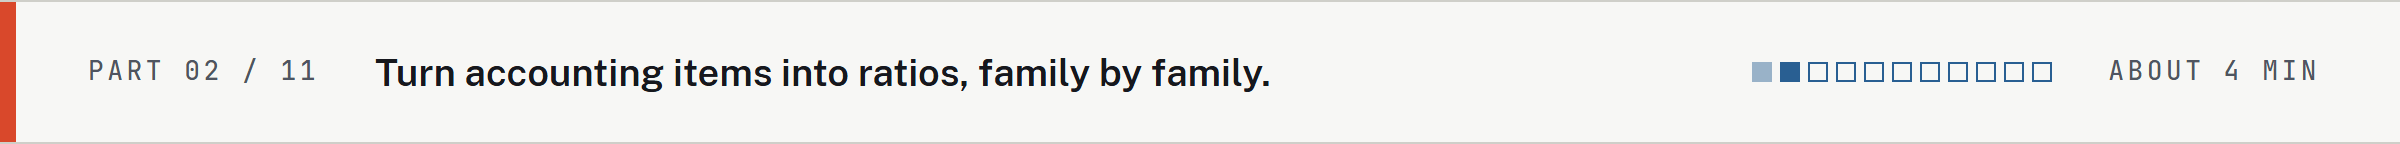

# From Amounts to Ratios

A accounting item mostly says how big a company is.
The **rank correlation** shows it: the correlation of two columns after each value is replaced by its rank.

Q. How closely does each accounting item follow total assets?

In [5]:
with_size = dev_panel[RAW_ITEMS].corrwith(dev_panel["total_assets"], method="spearman")
with_size = with_size.drop("total_assets").sort_values(ascending=False)
dollar_auc = roc_auc_score(dev_panel["target"], dev_panel["total_liabilities"])

store.put("size_corr_median", with_size.median())
store.put("liabilities_size_corr", with_size["total_liabilities"])
store.put("liabilities_dollar_auc", dollar_auc)

with_size.round(2).to_frame("rank correlation with total assets")

,rank correlation with total assets
current_assets,0.96
total_liabilities,0.96
depreciation_amort,0.95
total_current_liabilities,0.94
total_operating_expenses,0.93
net_sales,0.93
cogs,0.90
gross_profit,0.90
total_receivables,0.89
market_cap,0.88


**Reading.** The median item has a rank correlation of 0.89 with total assets, and total liabilities 0.96.
A large company owes a lot because it is large.

As a score for failure, total liabilities as an amount have a ROC-AUC of 0.51.
That is the chance that a positive row ranks above a negative one, and a coin scores a half.

A ratio divides one item by another, so the size cancels and the shape of the accounts is left.
Each family in the dictionary is one question a lender asks.

Q. How does the library build the ratios?

In [6]:
# taught: corp_default.features.add_ratios
def _nonzero(series: pd.Series) -> pd.Series:
    """A denominator with zeros blanked, so a ratio is NaN rather than infinite."""
    return series.replace(0, np.nan)


def _log_positive(series: pd.Series) -> pd.Series:
    return np.log(series.where(series > 0))


def add_ratios(frame: pd.DataFrame) -> pd.DataFrame:
    """Every ratio in FAMILIES, added as columns. A zero denominator gives NaN."""
    ta = _nonzero(frame["total_assets"])
    tl = _nonzero(frame["total_liabilities"])
    tcl = _nonzero(frame["total_current_liabilities"])
    sales = _nonzero(frame["net_sales"])
    ebitda = frame["ebitda"]
    return frame.assign(
        liabilities_to_assets=frame["total_liabilities"] / ta,
        lt_debt_to_assets=frame["total_lt_debt"] / ta,
        book_equity_to_assets=(frame["total_assets"] - frame["total_liabilities"]) / ta,
        debt_to_ebitda=(frame["total_lt_debt"] / ebitda).where(ebitda > 0),
        no_lt_debt=(frame["total_lt_debt"] == 0).astype(int),
        roa=frame["net_income"] / ta,
        ebit_to_assets=frame["ebit"] / ta,
        ebitda_to_assets=ebitda / ta,
        net_margin=frame["net_income"] / sales,
        ebitda_margin=ebitda / sales,
        gross_margin=frame["gross_profit"] / sales,
        negative_ebitda=(ebitda <= 0).astype(int),
        retained_earnings_to_assets=frame["retained_earnings"] / ta,
        current_ratio=frame["current_assets"] / tcl,
        quick_ratio=(frame["current_assets"] - frame["inventory"]) / tcl,
        working_capital_to_assets=(frame["current_assets"] - frame["total_current_liabilities"])
        / ta,
        current_assets_to_assets=frame["current_assets"] / ta,
        current_liabilities_to_liabilities=frame["total_current_liabilities"] / tl,
        ffo_to_liabilities=(frame["net_income"] + frame["depreciation_amort"]) / tl,
        asset_turnover=frame["net_sales"] / ta,
        mve_to_liabilities=frame["market_cap"] / tl,
        market_to_book_assets=(frame["market_cap"] + frame["total_liabilities"]) / ta,
        log_assets=_log_positive(frame["total_assets"]),
        log_market_cap=_log_positive(frame["market_cap"]),
    )

Three choices in the function matter later:

- a zero denominator gives a blank, never an infinite number;
- `debt_to_ebitda` is blank unless EBITDA is positive, because a negative EBITDA would make heavy debt look light, and `negative_ebitda` carries that fact instead;
- the two size ratios are logarithms, the scale Chapter 1 used for size.

Q. What do the ratios look like on the development rows?

In [7]:
RATIOS = [name for members in FAMILIES.values() for name in members]
FAMILY_OF = {name: family for family, members in FAMILIES.items() for name in members}
FLAGS = ["no_lt_debt", "negative_ebitda"]
CONTINUOUS = [name for name in RATIOS if name not in FLAGS]

ratios = add_ratios(raw)  # every row of the file, the last filings of failed companies included
features = panel.merge(ratios[[*KEYS, *RATIOS]], on=KEYS, validate="one_to_one")
assert len(features) == len(panel)
dev = development(features)
summary = dev[RATIOS].describe(percentiles=[0.01, 0.5, 0.99]).T

store.put("n_ratios", len(RATIOS))
store.put("n_families", len(FAMILIES))
store.put("n_continuous", len(CONTINUOUS))
store.put("leverage_median", summary.loc["liabilities_to_assets", "50%"])
store.put("leverage_max", summary.loc["liabilities_to_assets", "max"])
store.put("debt_to_ebitda_share", summary.loc["debt_to_ebitda", "count"] / len(dev))
store.put("current_ratio_median", summary.loc["current_ratio", "50%"])
store.put("current_assets_median", summary.loc["current_assets_to_assets", "50%"])
store.put(
    "current_rank_corr",
    dev["current_ratio"].corr(dev["current_assets_to_assets"], method="spearman"),
)

summary[["count", "min", "1%", "50%", "99%", "max"]].round(2)

,count,min,1%,50%,99%,max
liabilities_to_assets,55524.0,0.00,0.05,0.49,8.03,6324.00
lt_debt_to_assets,55524.0,0.00,0.00,0.09,1.34,308.80
book_equity_to_assets,55524.0,-6323.00,-7.03,0.51,0.95,1.00
debt_to_ebitda,39622.0,0.00,0.00,1.04,27.23,7629.46
no_lt_debt,55524.0,0.00,0.00,0.00,1.00,1.00
roa,55524.0,-1515.00,-6.34,0.02,0.37,244.83
ebit_to_assets,55524.0,-1241.00,-4.70,0.05,0.37,35.92
ebitda_to_assets,55524.0,-1224.00,-4.53,0.09,0.42,35.92
net_margin,55524.0,-29319.00,-75.58,0.02,0.60,1024.00
ebitda_margin,55524.0,-29325.70,-63.54,0.08,0.62,358.21


**Reading.** The medians are ordinary and the extremes are not.
The median firm-year has liabilities of 49% of assets, and one has 6,324 times its assets, because its assets are close to nothing.

`debt_to_ebitda` exists on 71% of the rows, those with a positive EBITDA.

A mean of such a column describes its few extreme rows.
So the chapter reads medians, quantiles, and ranks.

**Check.** `current_ratio` and `current_assets_to_assets` both start from current assets. Do they measure the same thing?

<details>
<summary>Show the answer</summary>

No.
Current assets over total assets say how much of the balance sheet is short-term, which is a mix of assets.

The current ratio divides by current liabilities, and says whether the short-term assets cover the short-term bills.
Only that one is a liquidity ratio, so only that one gets the name.

On the development rows their medians are 1.91 and 0.52, and their rank correlation is 0.50.

</details>

**Next, a way to look at columns with tails like these.**

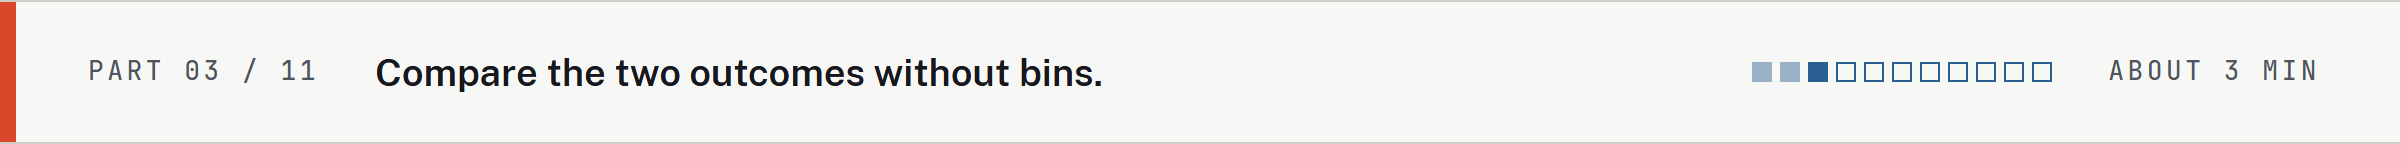

# Looking at Skewed Ratios

A histogram of these ratios needs bins and a place to cut the tails, and both choices change the picture.
The **ECDF** of Chapter 1 needs neither: at each value it shows the share of rows at or below it.

Each panel below frames the middle 90% of the development rows.

Q. How do positive and negative rows differ on six ratios?

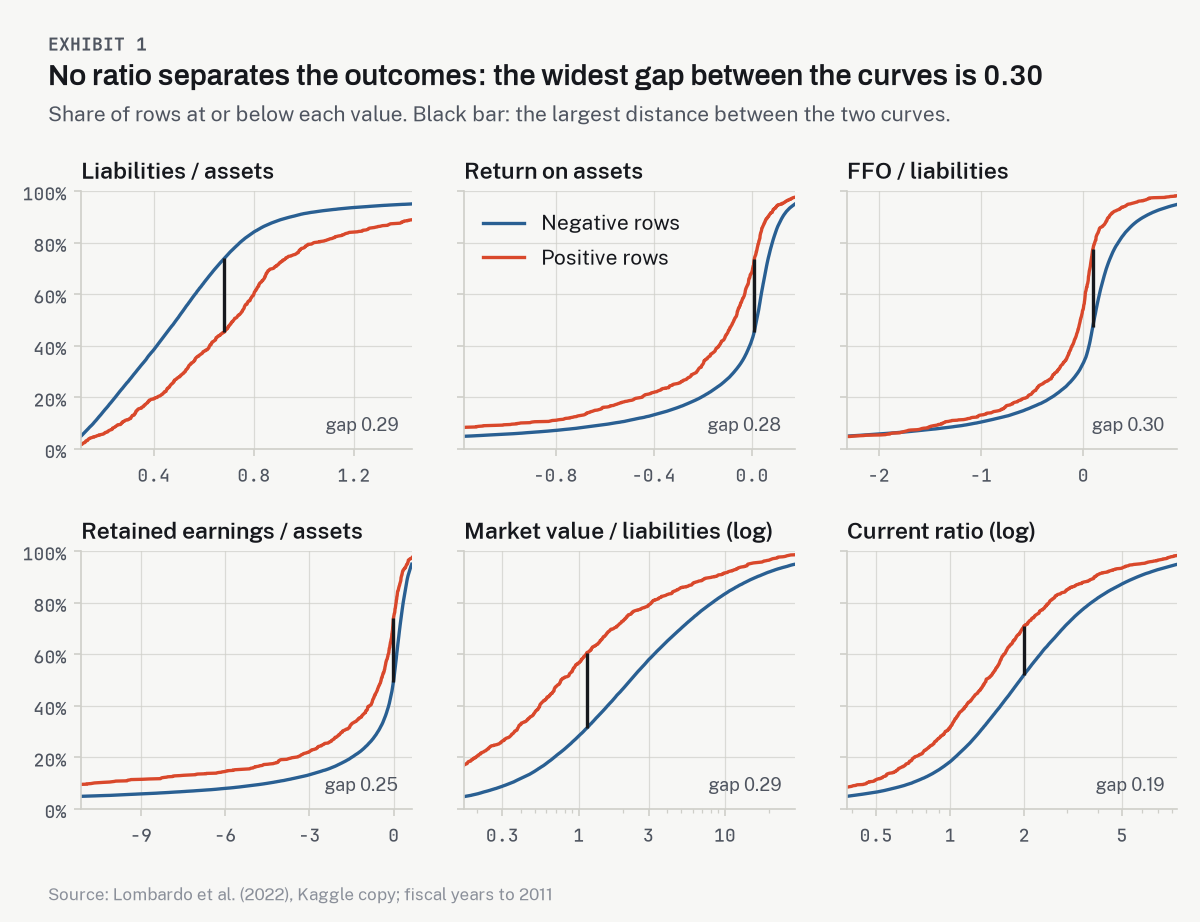

In [8]:
SHOWN = {  # ratio: the ticks of its log axis, or None for a plain axis
    "liabilities_to_assets": None,
    "roa": None,
    "ffo_to_liabilities": None,
    "retained_earnings_to_assets": None,
    "mve_to_liabilities": [0.3, 1, 3, 10, 30],
    "current_ratio": [0.5, 1, 2, 5],
}
FRAME = (0.05, 0.95)  # each panel runs between these quantiles of all development rows
positive, negative = dev.loc[dev["target"] == 1], dev.loc[dev["target"] == 0]


def ecdf(values: pd.Series) -> tuple[np.ndarray, np.ndarray]:
    """Sorted values, and the share of rows at or below each."""
    ordered = np.sort(values.dropna().to_numpy())
    return ordered, np.arange(1, len(ordered) + 1) / len(ordered)


# The largest distance between the two curves of a ratio.
tests = {name: ks_2samp(positive[name], negative[name]) for name in SHOWN}
gaps = pd.Series({name: test.statistic for name, test in tests.items()})
halfway = positive["liabilities_to_assets"].median()
above = dev.loc[dev["liabilities_to_assets"] > halfway, "target"]

store.put("frame_share", FRAME[1] - FRAME[0])
store.put("ecdf_gap", gaps.max())
store.put("ecdf_gap_name", gaps.idxmax())
store.put("leverage_pos_median", halfway)
store.put("leverage_neg_median", negative["liabilities_to_assets"].median())
store.put("neg_per_pos_above", (above == 0).sum() / (above == 1).sum())

fig, axes = plt.subplots(2, 3, figsize=(viz.EXHIBIT_WIDTH_IN, 4.8), sharey=True)
for ax, (name, log_ticks) in zip(axes.flat, SHOWN.items()):
    ax.plot(*ecdf(negative[name]), color=viz.SURVIVED, linewidth=1.6, label="Negative rows")
    ax.plot(*ecdf(positive[name]), color=viz.FAILED, linewidth=1.6, label="Positive rows")
    if log_ticks:
        viz.log_axis(ax)
        ax.set_xticks(log_ticks)
    else:
        ax.xaxis.set_major_locator(MaxNLocator(4))
    at = tests[name].statistic_location
    ax.vlines(at, (positive[name] <= at).mean(), (negative[name] <= at).mean(), color=viz.INK,
              linewidth=1.6, zorder=4)  # fmt: skip
    ax.set_xlim(*dev[name].quantile(FRAME))
    ax.set_title(viz.label(name, short=True) + (" (log)" if log_ticks else ""))
    ax.text(0.96, 0.07, f"gap {gaps[name]:.2f}", transform=ax.transAxes, ha="right", size=8.5,
            color=viz.SLATE)  # fmt: skip
axes[0, 0].set_ylim(0, 1)
axes[0, 0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[0, 1].legend(loc="upper left")
viz.exhibit(
    fig,
    f"No ratio separates the outcomes: the widest gap between the curves is {gaps.max():.2f}",
    "Share of rows at or below each value. Black bar: the largest distance between the two curves.",
    DEV_SOURCE,
)

**Reading.** In Exhibit 1 the two curves part in every panel, and never by much.
The black bar in each panel marks where they are furthest apart.
The widest of those gaps is 0.30, on `ffo_to_liabilities`.

Half of the positive rows have liabilities above 72% of assets, against 49% for the negative rows.
But above that level, negative rows still outnumber positive ones by 29 to one.

So a ratio shifts the odds and settles nothing alone.

**Next, how the shift builds up over the years.**

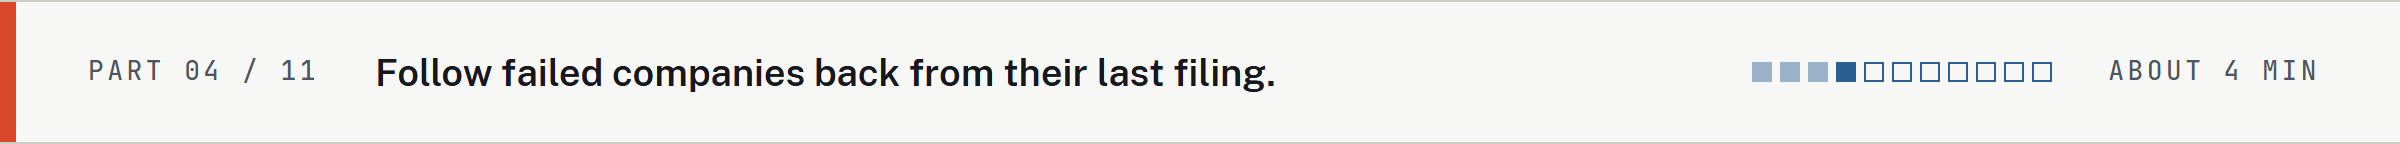

# Anatomy of a Failure

A positive row is one or two years from the end.
An **event study** lines the failed companies up on their last filing and looks back 8 years.

It takes the failed companies whose last filing is 2011 or earlier, so that each whole path lies in the development years.
It compares them with every firm-year to 2011 of all the other companies.

**Predict 1.** Take the median return on assets of the failed companies at each step of the path.
How many years before the last filing is it already below the median of the other companies?

Q. How do 9 ratios move over the years before a last filing?

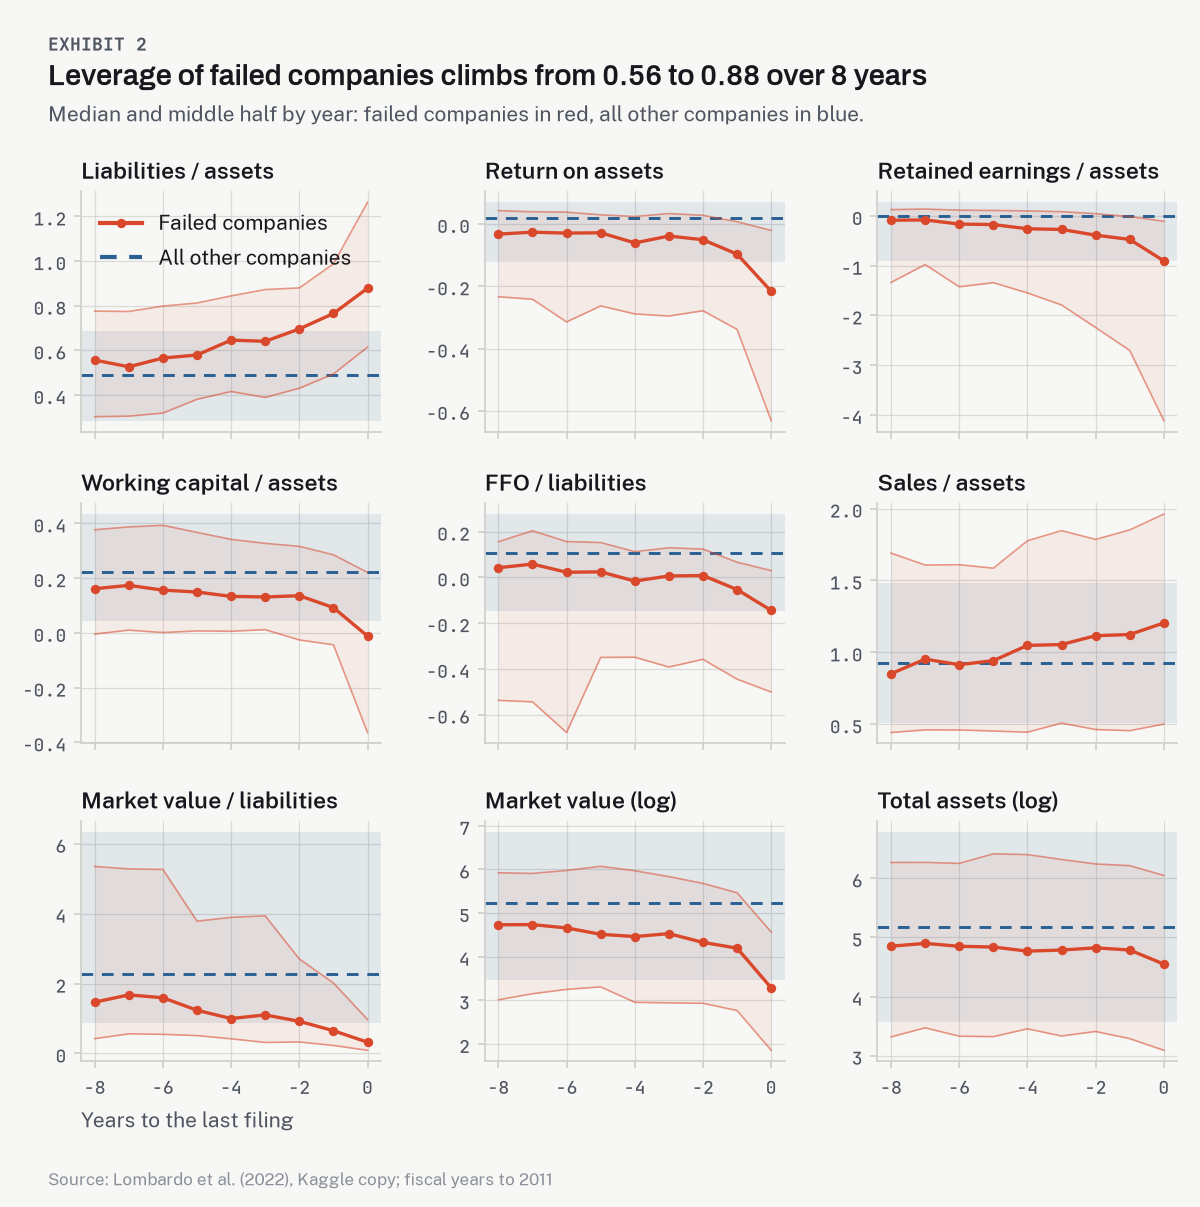

In [9]:
YEARS_BACK = 8
STUDY = [
    "liabilities_to_assets",
    "roa",
    "retained_earnings_to_assets",
    "working_capital_to_assets",
    "ffo_to_liabilities",
    "asset_turnover",
    "mve_to_liabilities",
    "log_market_cap",
    "log_assets",
]


def study_groups(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Rows to DEV_END: the last YEARS_BACK years of companies that failed by then, and all others."""
    last_filing = frame.groupby("company_name")["year"].transform("max")
    frame = frame.assign(
        years_to_final=last_filing - frame["year"],
        ended_failed=(frame["status_label"] == "failed") & (last_filing <= DEV_END),
    )
    frame = frame.loc[frame["year"] <= DEV_END]
    on_path = frame["ended_failed"] & (frame["years_to_final"] <= YEARS_BACK)
    return frame.loc[on_path], frame.loc[~frame["ended_failed"]]


QUARTILES = [0.25, 0.5, 0.75]
PATH_LEGEND = [
    Line2D([], [], color=viz.FAILED, marker="o", markersize=3.5, label="Failed companies"),
    Line2D([], [], color=viz.SURVIVED, linestyle=(0, (4, 3)), label="All other companies"),
]


def draw_paths(
    paths: pd.DataFrame,
    others: pd.DataFrame,
    columns: list[str],
    nrows: int,
    titles: dict | None = None,
):
    """Median and middle half of each column along the path, over the same for the other companies."""
    along = paths.groupby("years_to_final")[columns].quantile(QUARTILES).unstack()
    level = others[columns].quantile(QUARTILES)
    fig, axes = plt.subplots(
        nrows, len(columns) // nrows, figsize=(viz.EXHIBIT_WIDTH_IN, 2.1 * nrows + 0.4), sharex=True
    )
    for ax, name in zip(axes.flat, columns):
        low, middle, high = (along[name][q] for q in QUARTILES)
        ax.axhspan(level.loc[0.25, name], level.loc[0.75, name], color=viz.SURVIVED, alpha=0.1,
                   linewidth=0)  # fmt: skip
        ax.axhline(level.loc[0.5, name], color=viz.SURVIVED, linewidth=1.4, linestyle=(0, (4, 3)))
        # The failed band is an outline with a faint fill, so the two bands stay apart where they cross.
        ax.fill_between(-low.index, low, high, color=viz.FAILED, alpha=0.07, linewidth=0)
        for edge in (low, high):
            ax.plot(-edge.index, edge, color=viz.FAILED, linewidth=0.8, alpha=0.55)
        ax.plot(-middle.index, middle, color=viz.FAILED, marker="o", markersize=3.5, linewidth=1.6)
        ax.set_title(titles[name] if titles else viz.label(name, short=True))
        ax.set_xticks(range(-YEARS_BACK, 1, 2))
    # One label serves the row: every panel shares the axis.
    axes.flat[-(len(columns) // nrows)].set_xlabel("Years to the last filing", loc="left")
    axes.flat[0].legend(handles=PATH_LEGEND, loc="upper left")
    return fig, along.xs(0.5, axis=1, level=1), level


paths, others = study_groups(ratios)
in_view = paths.groupby("years_to_final")["company_name"].nunique()
fig, medians, level = draw_paths(paths, others, STUDY, nrows=3)
roa_below = medians["roa"] < level.loc[0.5, "roa"]
roa_outside = medians["roa"] < level.loc[0.25, "roa"]
# The reading says the median is below the others' in every year, and outside their middle half
# in the last year only. Checked here.
assert roa_below.all() and roa_outside.loc[0] and roa_outside.sum() == 1
assert medians.loc[0, "asset_turnover"] > medians.loc[YEARS_BACK, "asset_turnover"]

store.put("years_back", YEARS_BACK)
store.put("study_companies", in_view.loc[0])
store.put("study_companies_back", in_view.loc[YEARS_BACK])
store.put("study_ratios", len(STUDY))
store.put("leverage_back", medians.loc[YEARS_BACK, "liabilities_to_assets"])
store.put("leverage_final", medians.loc[0, "liabilities_to_assets"])
store.put("leverage_others", level.loc[0.5, "liabilities_to_assets"])
store.put("roa_final", medians.loc[0, "roa"])
store.put("mve_back", medians.loc[YEARS_BACK, "mve_to_liabilities"])
store.put("mve_final", medians.loc[0, "mve_to_liabilities"])
store.put("mve_others", level.loc[0.5, "mve_to_liabilities"])

viz.exhibit(
    fig,
    f"Leverage of failed companies climbs from {medians.loc[YEARS_BACK, 'liabilities_to_assets']:.2f} "
    f"to {medians.loc[0, 'liabilities_to_assets']:.2f} over {YEARS_BACK} years",
    "Median and middle half by year: failed companies in red, all other companies in blue.",
    DEV_SOURCE,
    save_as="ch3",
)

**Reading.** Exhibit 2 answers the chapter's question: failure shows early, as a long slide and then a fall.

The study follows 403 failed companies, and only 136 of them have accounts 8 years before their last filing.

At the start of the path, 8 years out, the median failed company already has liabilities of 56% of assets, against 49% for the others.
At its last filing it has 88%.

The median return on assets is below the others' median at every step, which answers Predict 1.
Yet it stays inside their middle half until the last filing, when it reaches -22%.

Market value falls from 1.5 times liabilities to 0.3, where the others' median is 2.3.
Sales over assets go the other way and rise, as the assets fall faster than the sales.

**Check.** The left end of each path rests on fewer companies than the right end. How could that alone bend a line?

<details>
<summary>Show the answer</summary>

The companies in view 8 years out are the ones with long histories.
If companies that live long start out stronger than companies that fail young, the line worsens toward the right even when no single company gets worse.

Following the same companies all the way rules that out, and the first extension of Your Turn does it.

</details>

**Next, from paths to rates.**

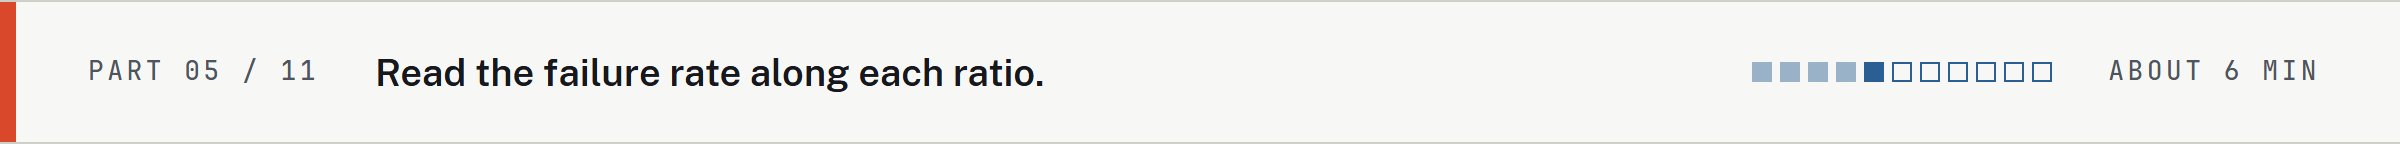

# Failure Rate Along Each Ratio

The event study starts from the failures.
A lender stands on the other side: given this ratio today, how often does failure follow?

Sort the development rows by a ratio, cut them into ten equal groups, the **deciles**, and take the share of positive rows in each.
A decile holds about 5,552 rows and, at the base rate, about 84 positives, so each rate needs an interval.

Chapter 2 drew Wilson intervals and left the building to this chapter.

Q. How does the library compute a Wilson interval?

In [10]:
# taught: corp_default.metrics.wilson_interval
def wilson_interval(k: int, n: int, z: float = 1.96) -> tuple[float, float]:
    """Wilson score interval for k successes in n trials."""
    if n <= 0:
        raise ValueError(f"wilson_interval needs n > 0, got n = {n}")
    p = k / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denominator
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator
    return max(0.0, center - half), min(1.0, center + half)

The interval is centered a little toward one half, and it never leaves the range from zero to one.
Both matter when the count of positives is small.

A curve is said to **turn** when it changes direction by more than its intervals allow.
The rule: some decile's whole interval lies on the wrong side of an earlier decile's interval.

Q. How does the failure rate move along 9 ratios?

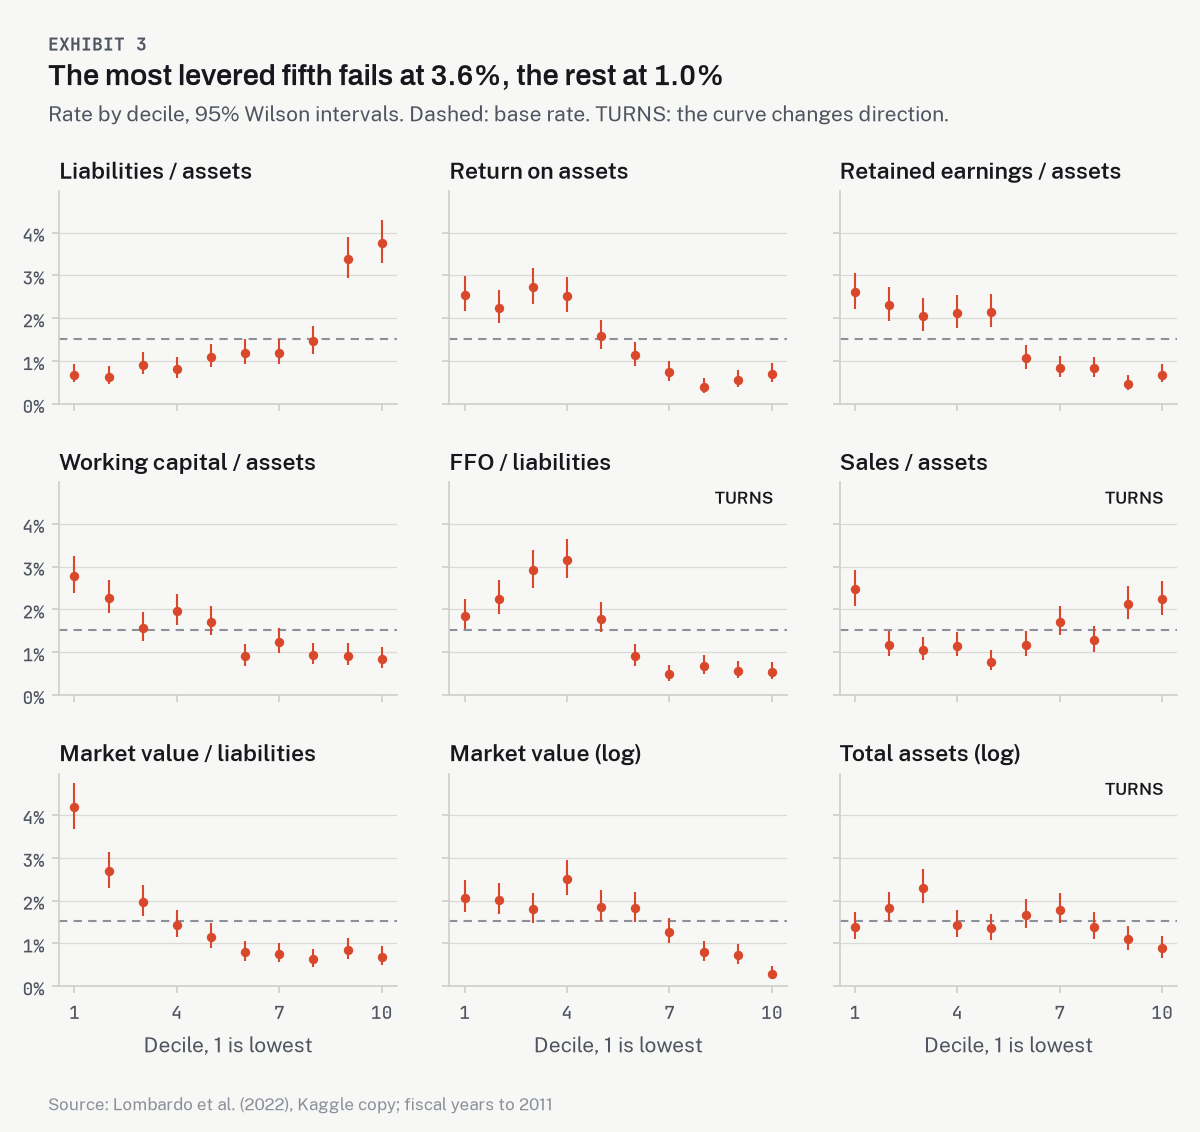

In [11]:
BINS = 10


def rate_by_bin(frame: pd.DataFrame, column: str) -> pd.DataFrame:
    """Two-year failure rate in each quantile bin of `column`, lowest first, with Wilson bounds."""
    rows = frame.dropna(subset=[column])
    bins = pd.qcut(rows[column], BINS, labels=False, duplicates="drop") + 1
    table = rows.groupby(bins)["target"].agg(positives="sum", rows="size")
    table["rate"] = table["positives"] / table["rows"]
    bounds = [wilson_interval(int(k), int(n)) for k, n in zip(table["positives"], table["rows"])]
    return table.join(pd.DataFrame(bounds, index=table.index, columns=["low", "high"]))


def turns(table: pd.DataFrame) -> bool:
    """True when a later bin's interval lies wholly on the wrong side of an earlier bin's."""
    rising = table["rate"].iloc[-1] > table["rate"].iloc[0]
    low, high = table["low"].to_numpy(), table["high"].to_numpy()
    pairs = [(i, j) for i in range(len(table)) for j in range(i + 1, len(table))]
    return any(high[j] < low[i] if rising else low[j] > high[i] for i, j in pairs)


def bars(table: pd.DataFrame) -> list[pd.Series]:
    """The distance from each rate down to its lower bound and up to its upper one."""
    return [table["rate"] - table["low"], table["high"] - table["rate"]]


base = dev["target"].mean()
curves = {name: rate_by_bin(dev, name) for name in CONTINUOUS}
turning = [name for name, table in curves.items() if turns(table)]
# The reading says three of the panels turn. Checked here.
assert [name for name in STUDY if name in turning] == [
    "ffo_to_liabilities",
    "asset_turnover",
    "log_assets",
]

leverage = curves["liabilities_to_assets"]
top_fifth = leverage.loc[BINS - 1 :, ["positives", "rows"]].sum()
the_rest = leverage.loc[: BINS - 2, ["positives", "rows"]].sum()
top_rate, rest_rate = (part["positives"] / part["rows"] for part in (top_fifth, the_rest))

store.put("decile_rows", round(len(dev) / BINS))
store.put("decile_positives", len(dev) / BINS * base)
store.put("top_fifth_rate", top_rate)
store.put("rest_rate", rest_rate)
store.put("leverage_low_min", leverage.loc[: BINS - 2, "rate"].min())
store.put("leverage_low_max", leverage.loc[: BINS - 2, "rate"].max())

fig, axes = plt.subplots(3, 3, figsize=(viz.EXHIBIT_WIDTH_IN, 6.2), sharex=True, sharey=True)
for ax, name in zip(axes.flat, STUDY):
    table = curves[name]
    ax.axhline(base, color=viz.MIST, linewidth=1, linestyle=(0, (4, 3)))
    ax.errorbar(table.index, table["rate"], yerr=bars(table), fmt="o", color=viz.FAILED,
                markersize=3.5, linewidth=1)  # fmt: skip
    ax.set_title(viz.label(name, short=True))
    if name in turning:
        ax.text(0.96, 0.9, "TURNS", transform=ax.transAxes, ha="right", size=8, weight=600)
    ax.set_xticks([1, 4, 7, 10])
    ax.grid(axis="x", visible=False)
axes[0, 0].set_ylim(0, None)
axes[0, 0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
for ax in axes[-1]:
    ax.set_xlabel("Decile, 1 is lowest")
viz.exhibit(
    fig,
    f"The most levered fifth fails at {top_rate:.1%}, the rest at {rest_rate:.1%}",
    "Rate by decile, 95% Wilson intervals. Dashed: base rate. TURNS: the curve changes direction.",
    DEV_SOURCE,
)

**Reading.** In Exhibit 3 leverage does little over most of its range and a great deal at the top.
Across its lowest eight deciles the rate stays between 0.6% and 1.5%.

In the top two it is 3.6%, against 1.0% for all the rest.

Three panels are marked, because their curves change direction.

Q. Which of the 22 ratios that are not yes-or-no flags turn?

In [12]:
shape = pd.DataFrame(
    {
        "family": {name: FAMILY_OF[name] for name in curves},
        "riskiest bin": {name: int(table["rate"].idxmax()) for name, table in curves.items()},
        "bins": {name: len(table) for name, table in curves.items()},
        "lowest rate": {name: table["rate"].min() for name, table in curves.items()},
        "highest rate": {name: table["rate"].max() for name, table in curves.items()},
    }
)

store.put("n_turning", len(turning))
store.put("ffo_peak_bin", shape.loc["ffo_to_liabilities", "riskiest bin"])
store.put("ffo_peak_rate", shape.loc["ffo_to_liabilities", "highest rate"])
store.put("ffo_first_rate", curves["ffo_to_liabilities"].loc[1, "rate"])

shape.loc[turning].round(4)

,family,riskiest bin,bins,lowest rate,highest rate
ffo_to_liabilities,coverage,4,10,0.0049,0.0315
asset_turnover,activity,1,10,0.0077,0.0247
market_to_book_assets,market,2,10,0.0092,0.0249
log_assets,size,3,10,0.0088,0.0231


**Reading.** Of the 22 ratios, 4 turn.
`ffo_to_liabilities` is riskiest in decile 4, at 3.2%, and not in the lowest, at 1.9%.

`asset_turnover` is risky at both ends.
A model that draws one straight line through a ratio misreads curves like these.

The same rate can be cut by industry.
A division with fewer than 100 development rows is left out.

Q. Does the failure rate differ by SIC division?

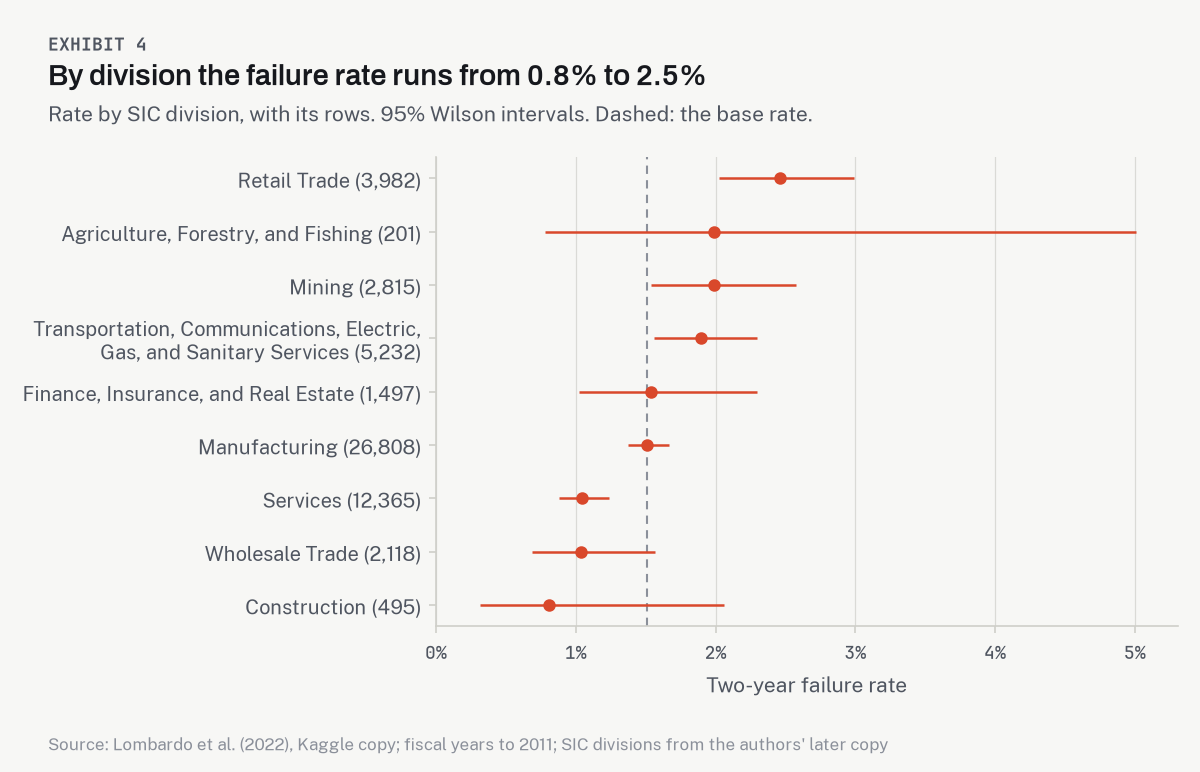

In [13]:
DIVISIONS = {  # the divisions of the SIC Manual, as in Chapter 1
    "A": "Agriculture, Forestry, and Fishing",
    "B": "Mining",
    "C": "Construction",
    "D": "Manufacturing",
    "E": "Transportation, Communications, Electric, Gas, and Sanitary Services",
    "F": "Wholesale Trade",
    "G": "Retail Trade",
    "H": "Finance, Insurance, and Real Estate",
    "I": "Services",
    "J": "Public Administration",
}
MIN_DIVISION_ROWS = 100

industry = load_industry()
division = dev["company_name"].map(industry["division"])
by_division = dev.groupby(division)["target"].agg(positives="sum", rows="size")
by_division = by_division.loc[by_division["rows"] >= MIN_DIVISION_ROWS]
by_division["rate"] = by_division["positives"] / by_division["rows"]
bounds = [
    wilson_interval(int(k), int(n)) for k, n in zip(by_division["positives"], by_division["rows"])
]
by_division = by_division.join(
    pd.DataFrame(bounds, index=by_division.index, columns=["low", "high"])
).sort_values("rate")
# The reading names retail trade as the highest and construction as the lowest. Checked here.
assert by_division.index[-1] == "G" and by_division.index[0] == "C"

store.put("min_division_rows", MIN_DIVISION_ROWS)
store.put("retail_rate", by_division.loc["G", "rate"])
store.put("construction_rate", by_division.loc["C", "rate"])
store.put("construction_positives", by_division.loc["C", "positives"])
store.put("manufacturing_rate", by_division.loc["D", "rate"])
store.put("manufacturing_share", by_division.loc["D", "rows"] / len(dev))
store.put("services_rate", by_division.loc["I", "rate"])

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.8))
place = np.arange(len(by_division))
ax.axvline(base, color=viz.MIST, linewidth=1, linestyle=(0, (4, 3)))
ax.errorbar(by_division["rate"], place, xerr=bars(by_division), fmt="o", color=viz.FAILED,
            markersize=5, linewidth=1.2)  # fmt: skip
ax.set_yticks(
    place,
    [
        textwrap.fill(f"{DIVISIONS[letter]} ({rows:,})", 44)
        for letter, rows in by_division["rows"].items()
    ],
)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, by_division["high"].max() * 1.06)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Two-year failure rate")
viz.exhibit(
    fig,
    f"By division the failure rate runs from {by_division['rate'].min():.1%} "
    f"to {by_division['rate'].max():.1%}",
    "Rate by SIC division, with its rows. 95% Wilson intervals. Dashed: the base rate.",
    f"{DEV_SOURCE}; SIC divisions from the authors' later copy",
)

**Reading.** In Exhibit 4 retail trade is highest, at 2.5%.
Construction is lowest at 0.8%, on 4 positive rows.

Manufacturing is 48% of the rows and sits on the base rate, at 1.5%, and services are at 1.0%.

Most of the intervals overlap, so industry is a weak signal beside the ratios.
Chapter 5 tests whether it earns a place in a model.

**Next, the weak end of the scale.**

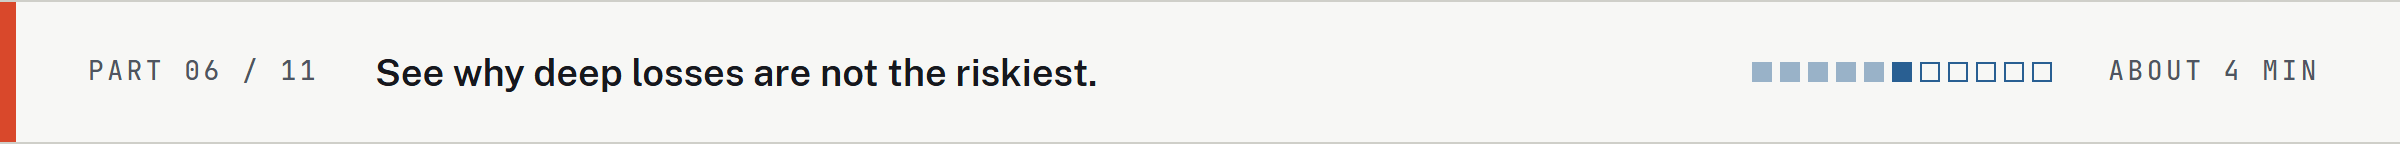

# Why the Worst-Looking Companies Are Not the Riskiest

In Exhibit 3 the lowest decile of `roa` fails no more often than the third.
The companies with the largest losses are not the ones that fail most.

One group stands out among them: firm-years with no long-term debt at all, which are 26% of the development rows.
Over all deciles they fail at 1.12%, against 1.65% for the rest.

**Predict 2.** In the lowest decile of return on assets, which fail more often: the firm-years with long-term debt, or those without?

Q. How does the failure rate along `roa` differ with and without long-term debt?

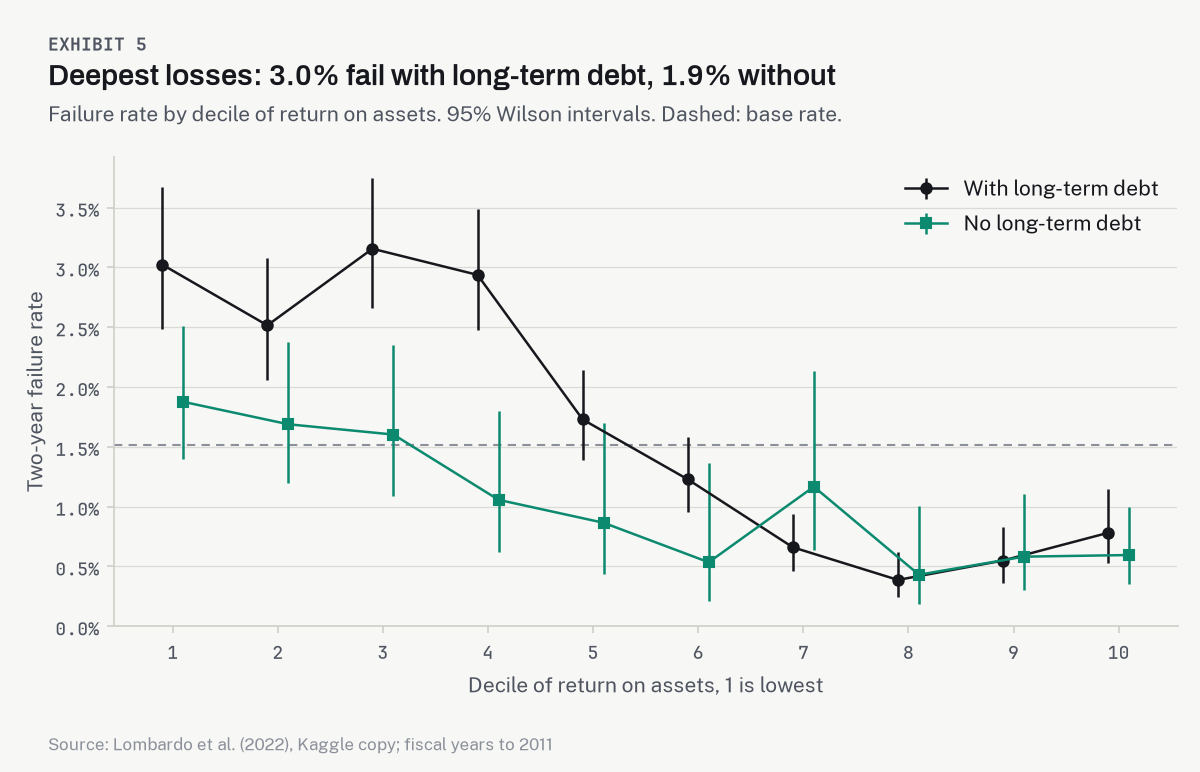

In [14]:
roa_decile = pd.qcut(dev["roa"], BINS, labels=False) + 1
by_debt = dev.groupby(["no_lt_debt", roa_decile])["target"].agg(positives="sum", rows="size")
by_debt["rate"] = by_debt["positives"] / by_debt["rows"]
bounds = [wilson_interval(int(k), int(n)) for k, n in zip(by_debt["positives"], by_debt["rows"])]
by_debt = by_debt.join(pd.DataFrame(bounds, index=by_debt.index, columns=["low", "high"]))
with_debt, debt_free = by_debt.loc[0], by_debt.loc[1]

loss_deciles = int((dev.groupby(roa_decile)["roa"].max() < 0).sum())
overall = dev.groupby("no_lt_debt")["target"].mean()
# The text says the lowest decile fails no more often than the third, and that the debt-free
# line is the lower one in every loss-making decile. Checked here.
assert curves["roa"].loc[1, "rate"] <= curves["roa"].loc[3, "rate"]
assert (debt_free.loc[:loss_deciles, "rate"] < with_debt.loc[:loss_deciles, "rate"]).all()

store.put("debt_free_share", dev["no_lt_debt"].mean())
store.put("debt_free_rate", overall.loc[1])
store.put("with_debt_rate", overall.loc[0])
store.put("weak_with_debt", with_debt.loc[1, "rate"])
store.put("weak_debt_free", debt_free.loc[1, "rate"])
store.put("weak_debt_free_share", debt_free.loc[1, "rows"] / by_debt.xs(1, level=1)["rows"].sum())
store.put("loss_deciles", loss_deciles)
store.put("with_debt_loss_min", with_debt.loc[:loss_deciles, "rate"].min())
store.put("with_debt_loss_max", with_debt.loc[:loss_deciles, "rate"].max())

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.8))
ax.axhline(base, color=viz.MIST, linewidth=1, linestyle=(0, (4, 3)))
for table, label, color, marker, nudge in (
    (with_debt, "With long-term debt", viz.INK, "o", -0.1),
    (debt_free, "No long-term debt", viz.ACCENT, "s", 0.1),
):
    ax.errorbar(table.index + nudge, table["rate"], yerr=bars(table), fmt=f"{marker}-",
                color=color, markersize=5, linewidth=1.2, label=label)  # fmt: skip
ax.set_xticks(range(1, BINS + 1))
ax.set_ylim(0, None)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax.grid(axis="x", visible=False)
ax.set_xlabel("Decile of return on assets, 1 is lowest")
ax.set_ylabel("Two-year failure rate")
ax.legend(loc="upper right")
viz.exhibit(
    fig,
    f"Deepest losses: {with_debt.loc[1, 'rate']:.1%} fail with long-term debt, "
    f"{debt_free.loc[1, 'rate']:.1%} without",
    "Failure rate by decile of return on assets. 95% Wilson intervals. Dashed: base rate.",
    DEV_SOURCE,
)

**Reading.** In Exhibit 5 the debt-free line runs below the other in every loss-making decile.
In the lowest decile 1.9% of the debt-free firm-years fail, against 3.0% of those with debt.

The lowest decile is also where the debt-free companies gather: they are 42% of it.
With no long-term lender, a loss ends in a bankruptcy filing less often.

That is half of the answer.
The line for companies with debt is flat too: over the 4 loss-making deciles it stays between 2.5% and 3.2%.

So in this file a loss raises the risk, and a deeper loss does not raise it further.

The same thing bends a classic score.
Altman's Z, the yardstick of Chapter 2, adds up five ratios so that a low score means distress.

Q. Is the lowest decile of Z the riskiest?

In [15]:
z = altman_z(dev)
z_table = rate_by_bin(dev.assign(z=z), "z")
z_table["debt-free share"] = dev["no_lt_debt"].groupby(pd.qcut(z, BINS, labels=False) + 1).mean()

store.put("z_lowest", z_table.loc[1, "rate"])
store.put("z_second", z_table.loc[2, "rate"])
store.put("z_lowest_debt_free", z_table.loc[1, "debt-free share"])
store.put("z_second_debt_free", z_table.loc[2, "debt-free share"])

z_table.head(4).round(4)

,positives,rows,rate,low,high,debt-free share
z,,,,,,
1,163,5553,0.0294,0.0252,0.0341,0.4019
2,172,5552,0.0310,0.0267,0.0359,0.2129
3,136,5552,0.0245,0.0207,0.0289,0.0857
4,90,5553,0.0162,0.0132,0.0199,0.0845


**Reading.** The lowest decile of Z fails at 2.94% and the second lowest at 3.10%.
Their intervals overlap, so the fair reading is that the score stops ranking at its weak end.

The lowest decile is 40% debt-free, against 21% for the second.
Chapter 4 measures what this costs the score.

**Next, each ratio scored alone.**

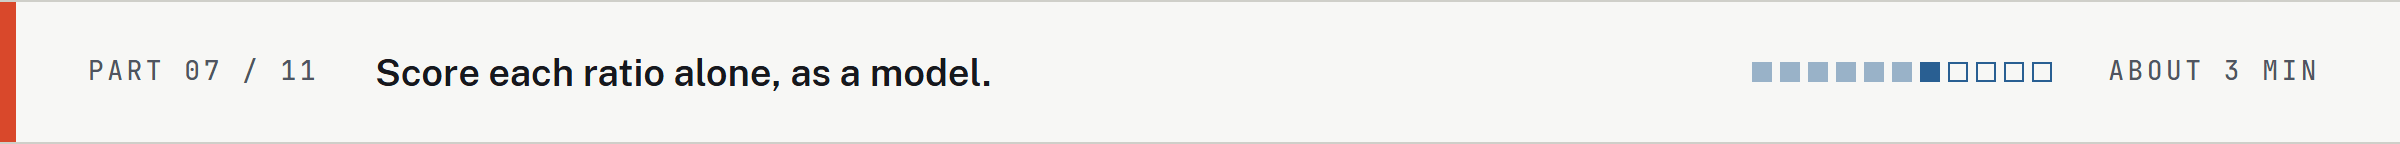

# Ranking the Signals One at a Time

Each ratio can be scored alone, as if it were a model.
The score is the ROC-AUC again.

A ratio whose low values are the risky ones scores below a half.
Its score is turned over, so that every score reads the same way: a half is a coin, and one is perfect.

Each score gets a 95% interval from a **cluster bootstrap**.
The companies are drawn again with replacement 1,000 times, each bringing all its rows, and the score is computed on every draw.

Chapter 4 builds that function and says why whole companies are drawn.
The cell below takes a minute or two.

Q. How well does each ratio rank the positive rows alone?

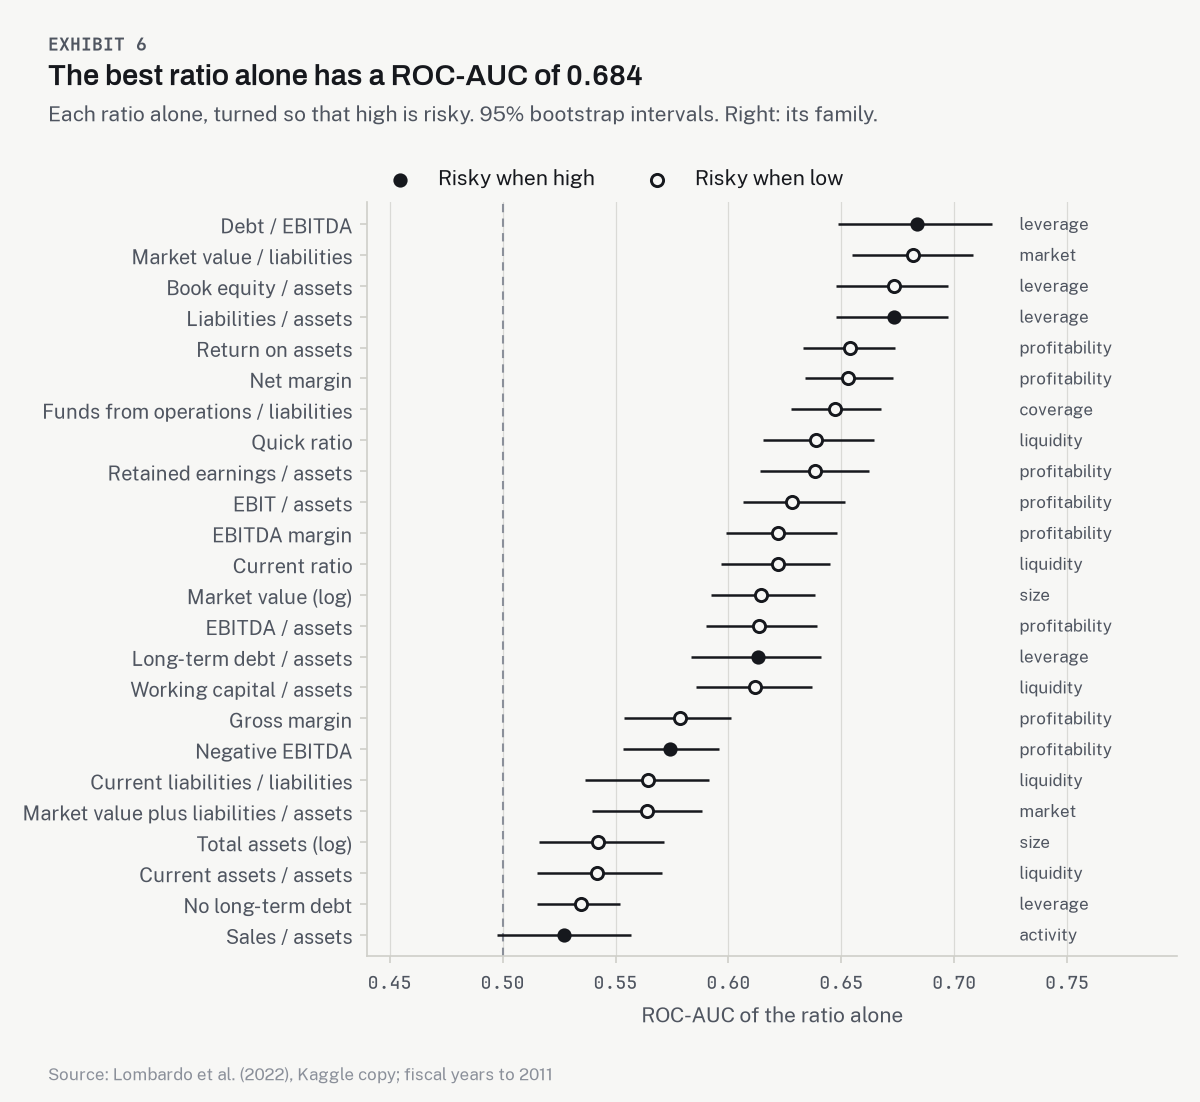

In [16]:
N_BOOT = 1000


def auc_of_levels(outcome: np.ndarray, level: np.ndarray) -> float:
    """ROC-AUC of a score given as whole-number ranks. Counting replaces sorting, so it is fast."""
    size = level.max() + 1
    positives = np.bincount(level, weights=outcome, minlength=size)
    negatives = np.bincount(level, weights=1 - outcome, minlength=size)
    below = np.cumsum(negatives) - negatives
    return (positives * (below + negatives / 2)).sum() / (positives.sum() * negatives.sum())


def ranked_alone(frame: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """Each column's ROC-AUC alone, turned so that high is risky, with a cluster-bootstrap interval."""
    rows = {}
    for name in columns:
        seen = frame.dropna(subset=[name])
        outcome = seen["target"].to_numpy()
        level = rankdata(seen[name], method="dense").astype(int) - 1
        score = auc_of_levels(outcome, level)
        low, high, _ = cluster_bootstrap_ci(
            outcome, level, seen["company_name"], auc_of_levels, n_boot=N_BOOT
        )
        if score < 0.5:
            score, low, high = 1 - score, 1 - high, 1 - low
            rows[name] = {"risky when": "low", "auc": score, "low": low, "high": high}
        else:
            rows[name] = {"risky when": "high", "auc": score, "low": low, "high": high}
    return pd.DataFrame(rows).T.astype({"auc": float, "low": float, "high": float})


alone = ranked_alone(dev, RATIOS).sort_values("auc")
# The fast score is the ROC-AUC of scikit-learn.
assert np.isclose(alone.loc["roa", "auc"], 1 - roc_auc_score(dev["target"], dev["roa"]))

every_row = alone.loc[[name for name in alone.index if dev[name].notna().all()]]
store.put("n_boot", N_BOOT)
store.put("best_auc", alone["auc"].max())
store.put("best_name", alone.index[-1])
store.put("best_every_row_auc", every_row["auc"].max())
store.put("best_every_row_name", every_row.index[-1])
store.put("leverage_auc", alone.loc["liabilities_to_assets", "auc"])
store.put("turnover_auc", alone.loc["asset_turnover", "auc"])

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 6.0))
place = np.arange(len(alone))
high_is_risky = (alone["risky when"] == "high").to_numpy()
ax.axvline(0.5, color=viz.MIST, linewidth=1, linestyle=(0, (4, 3)))
ax.hlines(place, alone["low"], alone["high"], color=viz.INK, linewidth=1.2)
ax.scatter(alone["auc"][high_is_risky], place[high_is_risky], s=34, color=viz.INK, zorder=3,
           label="Risky when high")  # fmt: skip
ax.scatter(alone["auc"][~high_is_risky], place[~high_is_risky], s=34, facecolor=viz.SHEET,
           edgecolor=viz.INK, linewidth=1.4, zorder=3, label="Risky when low")  # fmt: skip
edge = alone["high"].max() + 0.012
for y, name in zip(place, alone.index):
    ax.text(edge, y, FAMILY_OF[name], va="center", size=8, color=viz.SLATE)
ax.set_yticks(place, [viz.label(name) for name in alone.index])
ax.set_xlim(0.44, edge + 0.07)
ax.set_ylim(-0.7, len(alone) - 0.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("ROC-AUC of the ratio alone")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncols=2, borderaxespad=0.2)
viz.exhibit(
    fig,
    f"The best ratio alone has a ROC-AUC of {alone['auc'].max():.3f}",
    "Each ratio alone, turned so that high is risky. 95% bootstrap intervals. Right: its family.",
    DEV_SOURCE,
)

**Reading.** In Exhibit 6 leverage and market value lead, profitability and liquidity follow, and size and the asset mix trail.
The best, `debt_to_ebitda`, scores 0.684 on the rows where it exists, and `mve_to_liabilities` scores 0.682 on every row.

`liabilities_to_assets` scores 0.67.
As an amount, total liabilities scored 0.51: dividing by assets made the signal.

The intervals are wide, and most neighbors in the ranking cannot be told apart.

One score also hides the shape of Exhibit 3.
`asset_turnover` is risky at both ends, so it scores 0.53, close to a coin, while holding real information.

**Next, how much the ratios repeat each other.**

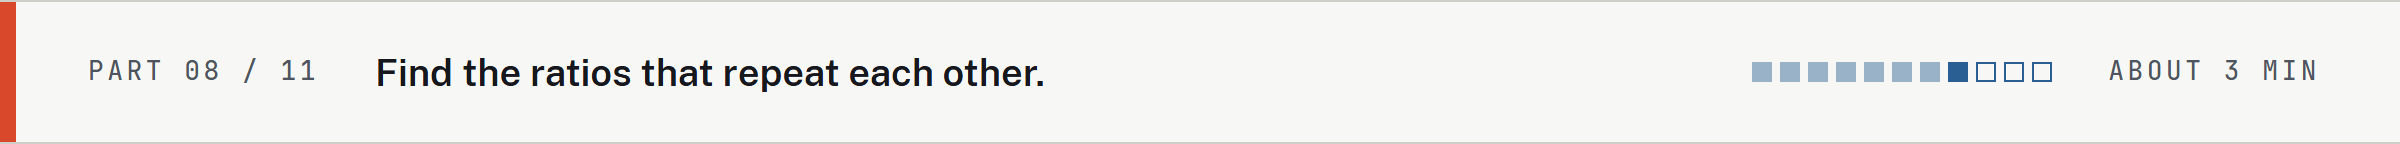

# Ratios That Repeat

Many of the ratios share a numerator or a denominator, so they repeat each other.
The rank correlation of each pair measures how much.

The exhibit puts the ratios in the order given by **hierarchical clustering**, which sets ratios that move together side by side.
The two flags are left out, because a rank correlation says little about a column of zeros and ones.

Q. Which ratios repeat each other?

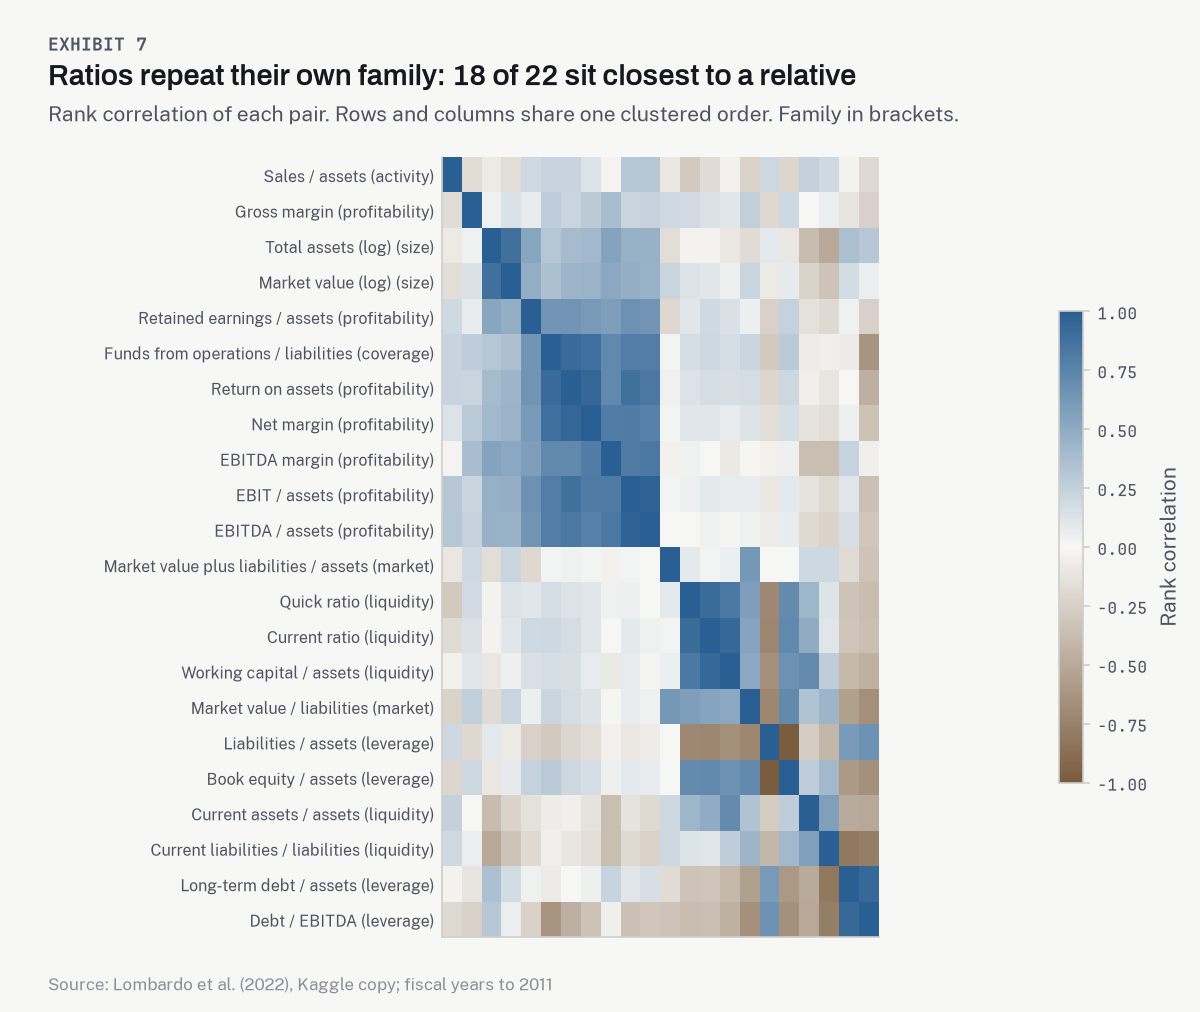

In [17]:
TWIN = 0.9  # a pair of ratios at or above this rank correlation, in size, is called a pair of twins

corr = dev[CONTINUOUS].corr(method="spearman")
distance = squareform(1 - corr.abs().to_numpy(), checks=False)
order = hierarchy.leaves_list(hierarchy.linkage(distance, method="average"))
corr = corr.iloc[order, order]

strength = corr.abs().where(~np.eye(len(corr), dtype=bool))
closest = strength.idxmax()
same_family = sum(FAMILY_OF[name] == FAMILY_OF[other] for name, other in closest.items())

store.put("same_family", same_family)
store.put("twin_level", TWIN)
store.put("twin_pairs", int((strength >= TWIN).sum().sum() / 2))
store.put("equity_leverage_corr", corr.loc["book_equity_to_assets", "liabilities_to_assets"])

diverging = LinearSegmentedColormap.from_list("diverging", ["#7A5C3E", viz.SHEET, viz.SURVIVED])
fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 5.4))
image = ax.imshow(corr.to_numpy(), cmap=diverging, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks([])
ax.set_yticks(range(len(corr)), [f"{viz.label(name)} ({FAMILY_OF[name]})" for name in corr.index])
ax.grid(visible=False)
ax.tick_params(length=0)
fig.colorbar(image, ax=ax, shrink=0.7, pad=0.02, label="Rank correlation")
viz.exhibit(
    fig,
    f"Ratios repeat their own family: {same_family} of {len(corr)} sit closest to a relative",
    "Rank correlation of each pair. Rows and columns share one clustered order. Family in brackets.",
    DEV_SOURCE,
)
for axis in fig.axes:
    axis.tick_params(labelsize=7.5)

**Reading.** Exhibit 7 has blocks along its diagonal, and each block is mostly one family.
For 18 of the 22 ratios the closest neighbor is inside their own family, so the families of the dictionary are in the data too.

There are 7 pairs with a rank correlation of 0.9 or more in size.
One pair is exact, at -1: `book_equity_to_assets` is one minus `liabilities_to_assets`.

A tree model can live with copies.
A linear model splits one effect across them, and Chapter 4 adds a penalty for that.

**Next, two ratios from different blocks, taken together.**

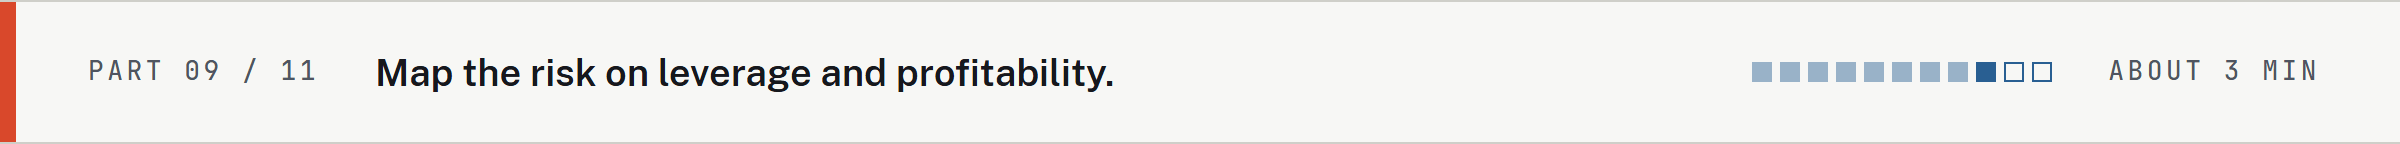

# The Risk Map

Leverage and return on assets sit in different blocks, so each carries news the other does not.

The map cuts the plane into hexagons and colors each by its failure rate.
A hexagon with fewer than 100 rows is left blank, because its rate would be noise.

A firm-year is called levered here when its liabilities over assets are in the top fifth.

Q. Where on the map do the failures gather?

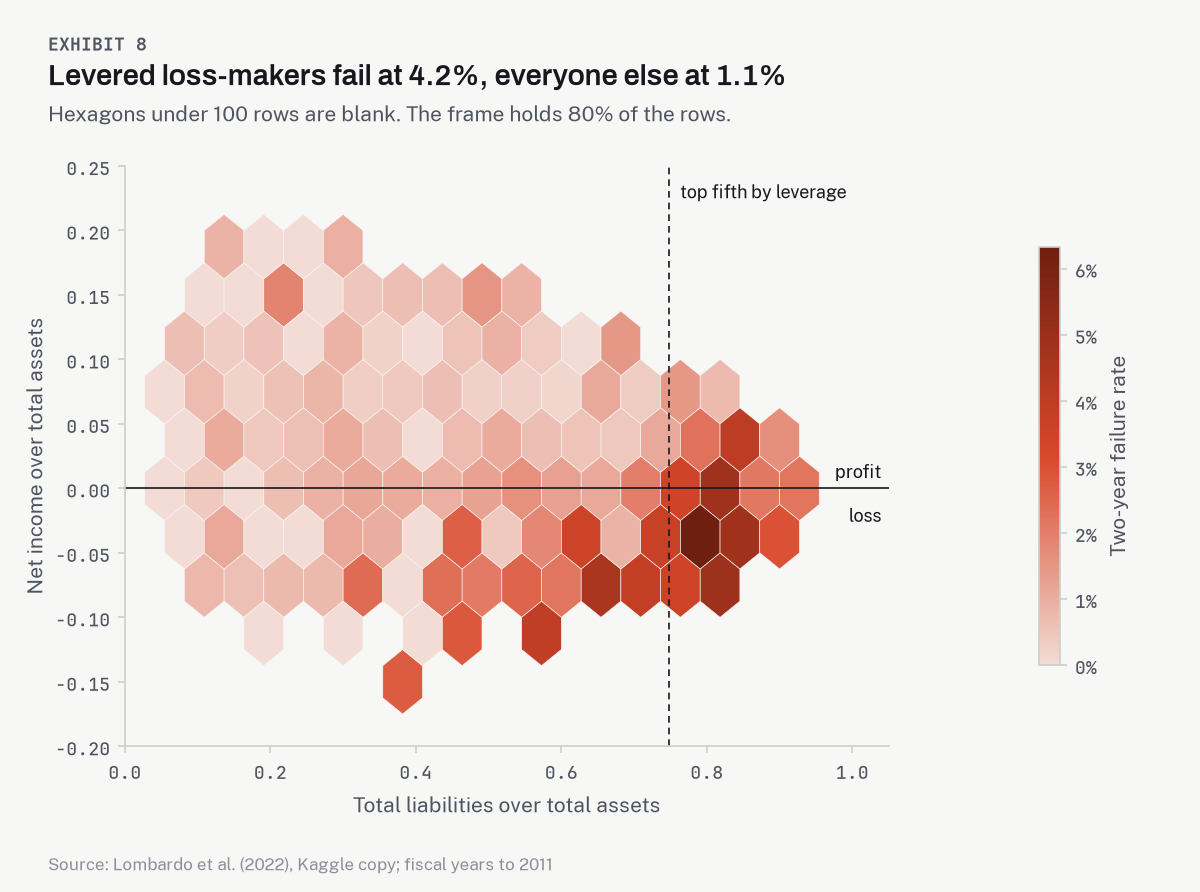

In [18]:
MAP_FRAME = {"liabilities_to_assets": (0.0, 1.2), "roa": (-0.3, 0.3)}
MAP_MIN_ROWS = 100
LEVERED = 0.8  # the quantile of liabilities over assets above which a firm-year is called levered

cut = dev["liabilities_to_assets"].quantile(LEVERED)
corner = dev.groupby(
    [(dev["liabilities_to_assets"] > cut).rename("levered"), (dev["roa"] < 0).rename("loss")]
)["target"].agg(positives="sum", rows="size")
corner["rate"] = corner["positives"] / corner["rows"]
both = corner.loc[(True, True)]
elsewhere = corner.drop(index=[(True, True)]).sum()

inside = np.logical_and.reduce([dev[name].between(*limits) for name, limits in MAP_FRAME.items()])
on_map = dev.loc[inside]

store.put("map_min_rows", MAP_MIN_ROWS)
store.put("levered_loss_rate", both["rate"])
store.put("levered_loss_rows", both["rows"] / len(dev))
store.put("levered_loss_positives", both["positives"] / dev["target"].sum())
store.put("levered_profit_rate", corner.loc[(True, False), "rate"])
store.put("unlevered_loss_rate", corner.loc[(False, True), "rate"])
store.put("neither_rate", corner.loc[(False, False), "rate"])

heat = LinearSegmentedColormap.from_list("heat", viz.RISK)
fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 4.6))
image = ax.hexbin(
    on_map["liabilities_to_assets"],
    on_map["roa"],
    C=on_map["target"],
    reduce_C_function=np.mean,
    gridsize=(22, 8),
    extent=(*MAP_FRAME["liabilities_to_assets"], *MAP_FRAME["roa"]),
    mincnt=MAP_MIN_ROWS,
    cmap=heat,
    linewidths=0.3,
    edgecolors=viz.SHEET,
)
ax.axhline(0, color=viz.INK, linewidth=0.8)
ax.axvline(cut, color=viz.INK, linewidth=0.8, linestyle=(0, (4, 3)))
ax.text(cut + 0.015, 0.225, "top fifth by leverage", size=8.5)
ax.text(1.04, 0.008, "profit", size=8.5, ha="right")
ax.text(1.04, -0.026, "loss", size=8.5, ha="right")
# The axes stop where the hexagons do; the frame behind them is unchanged.
ax.set_xlim(0, 1.05)
ax.set_ylim(-0.2, 0.25)
ax.grid(visible=False)
ax.set_xlabel("Total liabilities over total assets")
ax.set_ylabel("Net income over total assets")
# A bar the full height of the chart breaks the layout that exhibit() fits, so it is a little shorter.
fig.colorbar(image, ax=ax, shrink=0.85, pad=0.02, format=PercentFormatter(1.0, decimals=0),
             label="Two-year failure rate")  # fmt: skip
viz.exhibit(
    fig,
    f"Levered loss-makers fail at {both['rate']:.1%}, everyone else at "
    f"{elsewhere['positives'] / elsewhere['rows']:.1%}",
    f"Hexagons under {MAP_MIN_ROWS} rows are blank. The frame holds {inside.mean():.0%} of the rows.",
    DEV_SOURCE,
)

**Reading.** In Exhibit 8 the color deepens toward the lower right, where high leverage meets losses.
The levered firm-years that also report a loss fail at 4.2%.

They are 13% of the rows and hold 37% of the positives.

Each ratio alone says less.
Levered with a profit, the rate is 2.4%, and a loss without the leverage gives 1.7%.

With neither it is 0.6%.
So a model has to read one ratio in the light of the other, and Chapter 5 draws a tree's decisions over this map.

**Next, what a single year of ratios cannot show.**

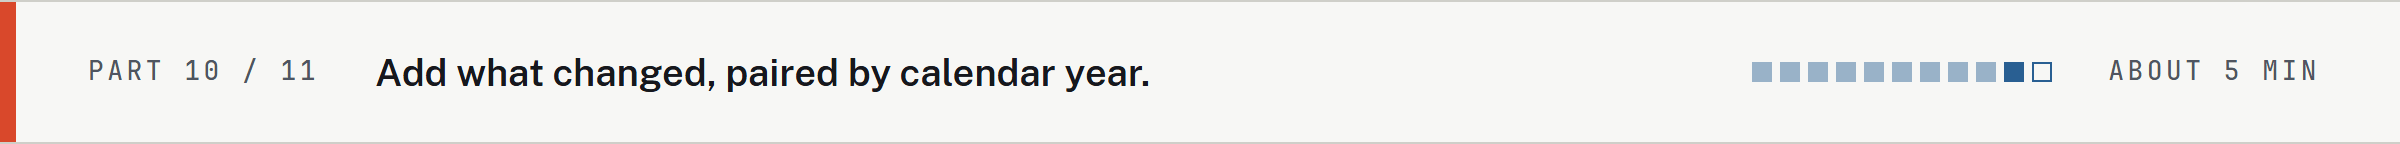

# What Changed Since Last Year

Exhibit 2 showed the ratios moving for years before a failure.
A row of ratios is one year, and the movement is not in it.

History puts it there, with the columns the dictionary lists.

There is one trap.
The usual way to find last year's value is to shift each company's rows down by one.

That pairs a row with the row before it, which is last year only if no year is missing.

Q. How many rows would a shift pair with the wrong year?

In [19]:
in_order = raw.sort_values(KEYS)
row_before = in_order.groupby("company_name")["year"].shift(1)
after_gap = in_order.loc[in_order["year"] - row_before > 1]

store.put("shift_mispaired", len(after_gap))
store.put("gap_companies", after_gap["company_name"].nunique())

pd.Series(
    {
        "rows with a row before them": int(row_before.notna().sum()),
        "rows whose row before is not last year": len(after_gap),
        "companies with such a row": after_gap["company_name"].nunique(),
    },
    name="the file",
).to_frame()

,the file
rows with a row before them,69711
rows whose row before is not last year,810
companies with such a row,710


**Reading.** A gap comes before 810 rows, in 710 companies.
A shift would hand each of them a change measured over two years or more and call it one year.

Q. How does the library pair the rows instead?

In [20]:
# taught: corp_default.features.add_history
def add_history(frame: pd.DataFrame, lags: tuple[int, ...] = (1, 2)) -> pd.DataFrame:
    """Changes, growth, and past losses against the same company `lag` calendar years earlier.

    Rows are paired by (company_name, year - lag), never by position, so a reporting gap gives
    NaN instead of pairing two years that are not `lag` apart.
    """
    keys = ["company_name", "year"]
    if frame.duplicated(keys).any():
        raise ValueError("add_history needs one row per (company_name, year)")
    by_key = frame.set_index(keys)
    logs = pd.DataFrame({name: _log_positive(by_key[item]) for name, item in GROWTH_ITEMS.items()})
    added = {}
    for lag in lags:
        earlier = pd.MultiIndex.from_arrays([frame["company_name"], frame["year"] - lag])
        past = by_key.reindex(earlier)
        past_logs = logs.reindex(earlier)
        for name in HISTORY_RATIOS:
            added[f"d{lag}_{name}"] = frame[name].to_numpy() - past[name].to_numpy()
        for name in GROWTH_ITEMS:
            added[f"g{lag}_{name}"] = logs[name].to_numpy() - past_logs[name].to_numpy()
        past_income = past["net_income"].to_numpy()
        added[f"loss_{lag}y_ago"] = np.where(
            np.isnan(past_income), np.nan, (past_income < 0).astype(float)
        )
    added["years_observed"] = frame.sort_values("year").groupby("company_name").cumcount() + 1
    return frame.assign(**added)

The function looks each row's partner up by company and calendar year.
A missing year gives a blank, never a wrong pair.

Q. What does the history of a company with a gap look like?

In [21]:
wide = add_history(ratios)
HISTORY = [name for name in feature_names() if name not in RATIOS]
features = features.merge(wide[[*KEYS, *HISTORY]], on=KEYS, validate="one_to_one")
dev = development(features)

filed = set(zip(raw["company_name"], raw["year"]))
changed = wide.loc[wide["d1_roa"].notna()]
wrong = sum((name, year - 1) not in filed for name, year in zip(changed["company_name"], changed["year"]))  # fmt: skip

store.put("calendar_mispaired", wrong)
store.put("n_history", len(HISTORY))
store.put("no_change_share", features["d1_roa"].isna().mean())

example = after_gap.iloc[0]  # the first row in the file that follows a gap
year_before_gap = int(row_before.loc[example.name])
near_gap = (wide["company_name"] == example["company_name"]) & wide["year"].between(
    year_before_gap - 1, example["year"] + 1
)
wide.loc[near_gap, [*KEYS, "roa", "d1_roa", "d2_roa", "years_observed"]].round(3)

,company_name,year,roa,d1_roa,d2_roa,years_observed
12362,C_1028,2004,0.096,-0.003,0.006,6
12363,C_1028,2005,0.070,-0.026,-0.029,7
12364,C_1028,2014,0.108,NaN,NaN,8
12365,C_1028,2015,0.179,0.071,NaN,9


**Reading.** The first row after the gap has no one-year change, because the year before it was never filed.
Across the file the calendar join pairs 0 rows with the wrong year.

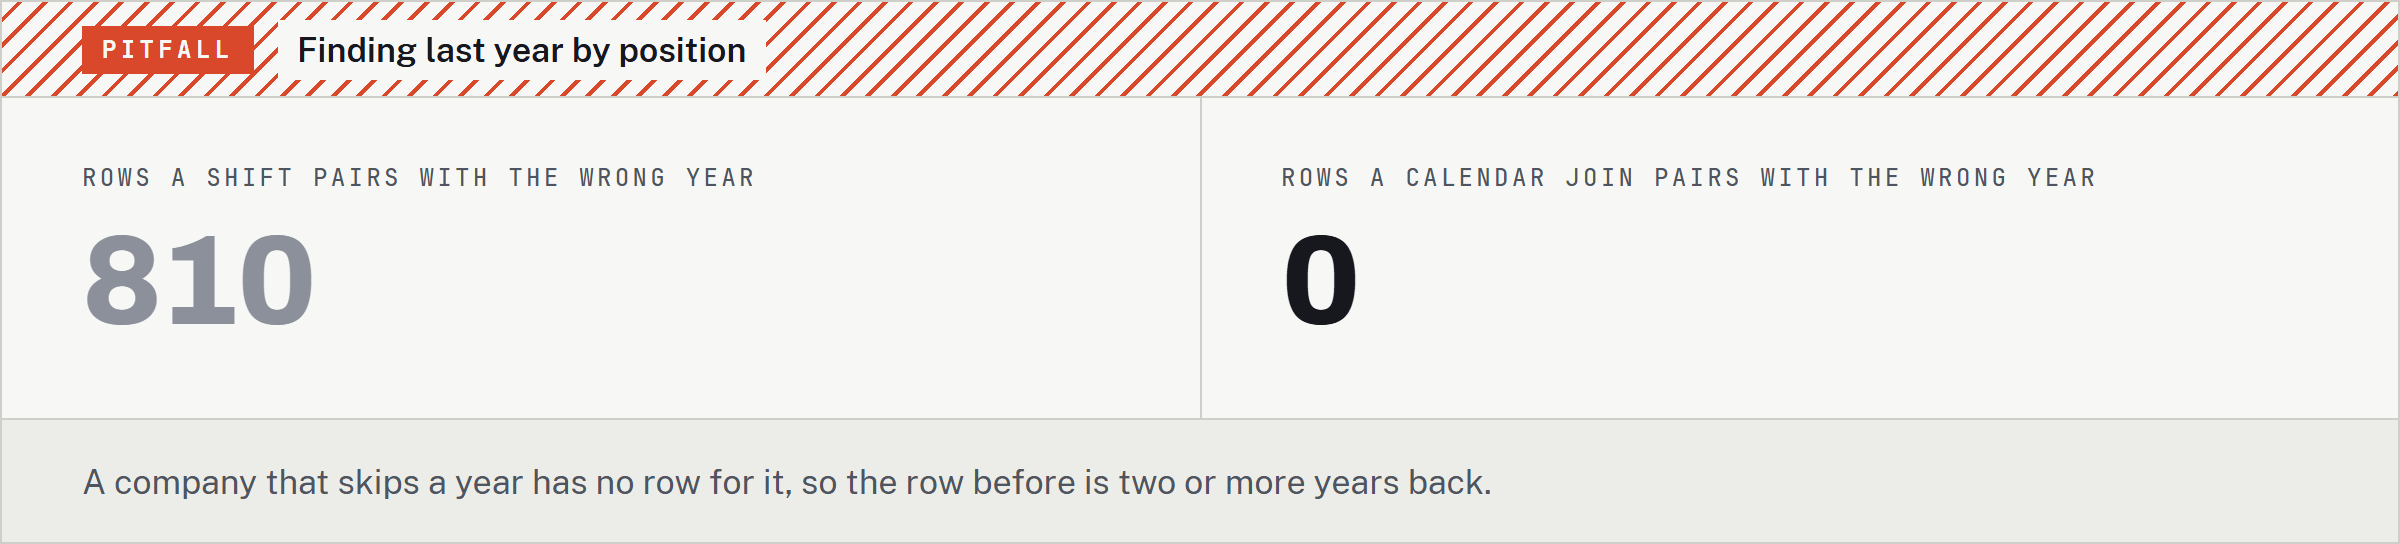

The history comes to 21 columns.
A one-year change is blank on 13% of the labeled rows, mostly a company's first year in the file.

Q. How do the changes move before a last filing?

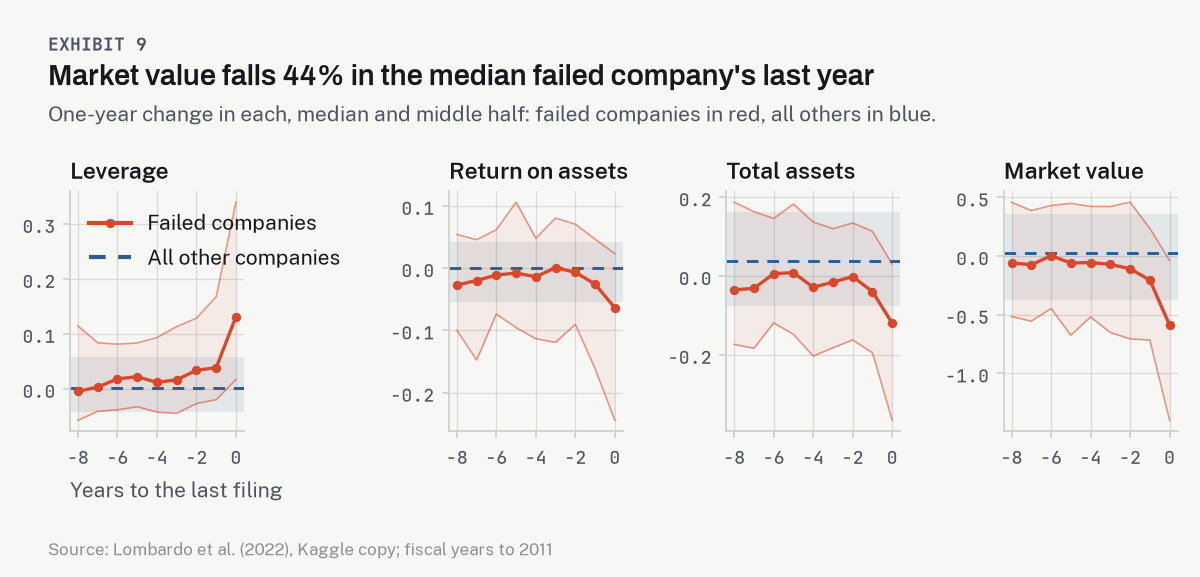

In [22]:
CHANGES = ["d1_liabilities_to_assets", "d1_roa", "g1_assets", "g1_market_cap"]

change_paths, change_others = study_groups(wide)
CHANGE_TITLES = {
    "d1_liabilities_to_assets": "Leverage",
    "d1_roa": "Return on assets",
    "g1_assets": "Total assets",
    "g1_market_cap": "Market value",
}
fig, changes, change_level = draw_paths(
    change_paths, change_others, CHANGES, nrows=1, titles=CHANGE_TITLES
)


def as_share(log_growth: float) -> float:
    """Growth in logarithms as a share: -0.5 is a fall of 39%."""
    return float(np.exp(log_growth) - 1)


def auc_alone(name: str) -> float:
    """ROC-AUC of one column on the rows where it exists, turned so that it is at least a half."""
    seen = dev.dropna(subset=[name])
    score = roc_auc_score(seen["target"], seen[name])
    return max(score, 1 - score)


history_auc = pd.Series({name: auc_alone(name) for name in HISTORY}).sort_values()

store.put("mcap_fall_final", -as_share(changes.loc[0, "g1_market_cap"]))
store.put("mcap_fall_prior", -as_share(changes.loc[1, "g1_market_cap"]))
store.put("mcap_growth_others", as_share(change_level.loc[0.5, "g1_market_cap"]))
store.put("leverage_change_final", changes.loc[0, "d1_liabilities_to_assets"])
store.put("best_history_name", history_auc.index[-1])
store.put("best_history_auc", history_auc.iloc[-1])

viz.exhibit(
    fig,
    f"Market value falls {-as_share(changes.loc[0, 'g1_market_cap']):.0%} "
    "in the median failed company's last year",
    "One-year change in each, median and middle half: failed companies in red, all others in blue.",
    DEV_SOURCE,
)

**Reading.** In Exhibit 9 the changes stay inside the others' middle half until the last year or two, and then break away.

In its last year the median failed company loses 44% of its market value, and its liabilities rise by 13% of assets.
The year before, the fall in market value is already 19%, where the others' median is a rise of 3%.

So a level shows early and a change shows late.
Scored alone, the best history column, `d2_liabilities_to_assets`, has a ROC-AUC of 0.62, below the best levels.

What the changes add on top of the levels is a question for a model, and Chapter 5 answers it.

**Next, whether the ratios themselves stay put.**

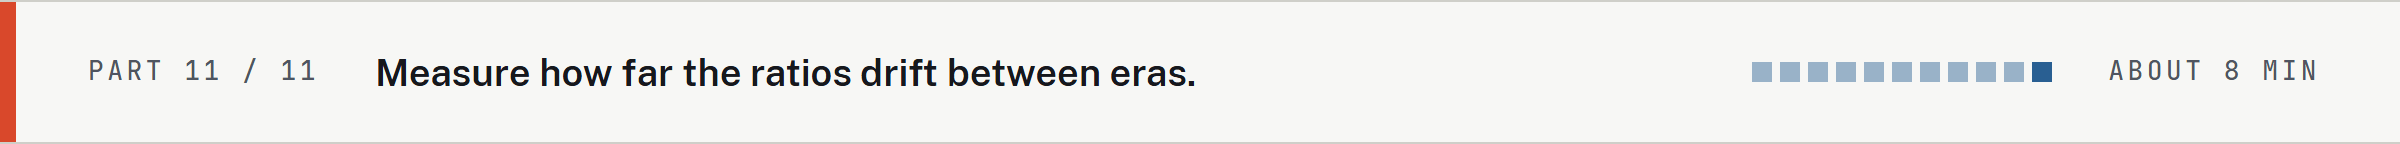

# The Ground Is Moving

A model is fitted on the past and used on the future.
If the ratios shift between the two, the model meets companies unlike the ones it learned from, and that shift is **drift**.

Three eras are compared: 1999 to 2006, 2007 to 2011, and 2014 to 2016, the years Chapter 7 is tested on.
Only ratios are read from the last era, and its outcomes stay sealed.

The **population stability index**, or PSI, measures the shift in one column.
It cuts the first era into ten equal bins, takes the share of each era in each bin, and adds up how far the shares differ.

It is zero when the shares match in every bin, and it grows as they part.

Q. How does the library compute it?

In [23]:
# taught: corp_default.metrics.psi
def psi(expected, actual, bins: int = 10) -> float:
    """Population stability index of `actual` against `expected`, on missing-free values.

    Bin edges are the quantiles of `expected`. Empty bins are floored at 1e-6 so the log is finite.
    """
    expected = np.asarray(expected, dtype=float)
    actual = np.asarray(actual, dtype=float)
    expected, actual = expected[~np.isnan(expected)], actual[~np.isnan(actual)]
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)[1:-1]))
    e = np.bincount(np.searchsorted(edges, expected, side="right"), minlength=len(edges) + 1)
    a = np.bincount(np.searchsorted(edges, actual, side="right"), minlength=len(edges) + 1)
    e = np.maximum(e / e.sum(), 1e-6)
    a = np.maximum(a / a.sum(), 1e-6)
    return float(np.sum((a - e) * np.log(a / e)))

Q. Which ratios drift most from the first era to the last?

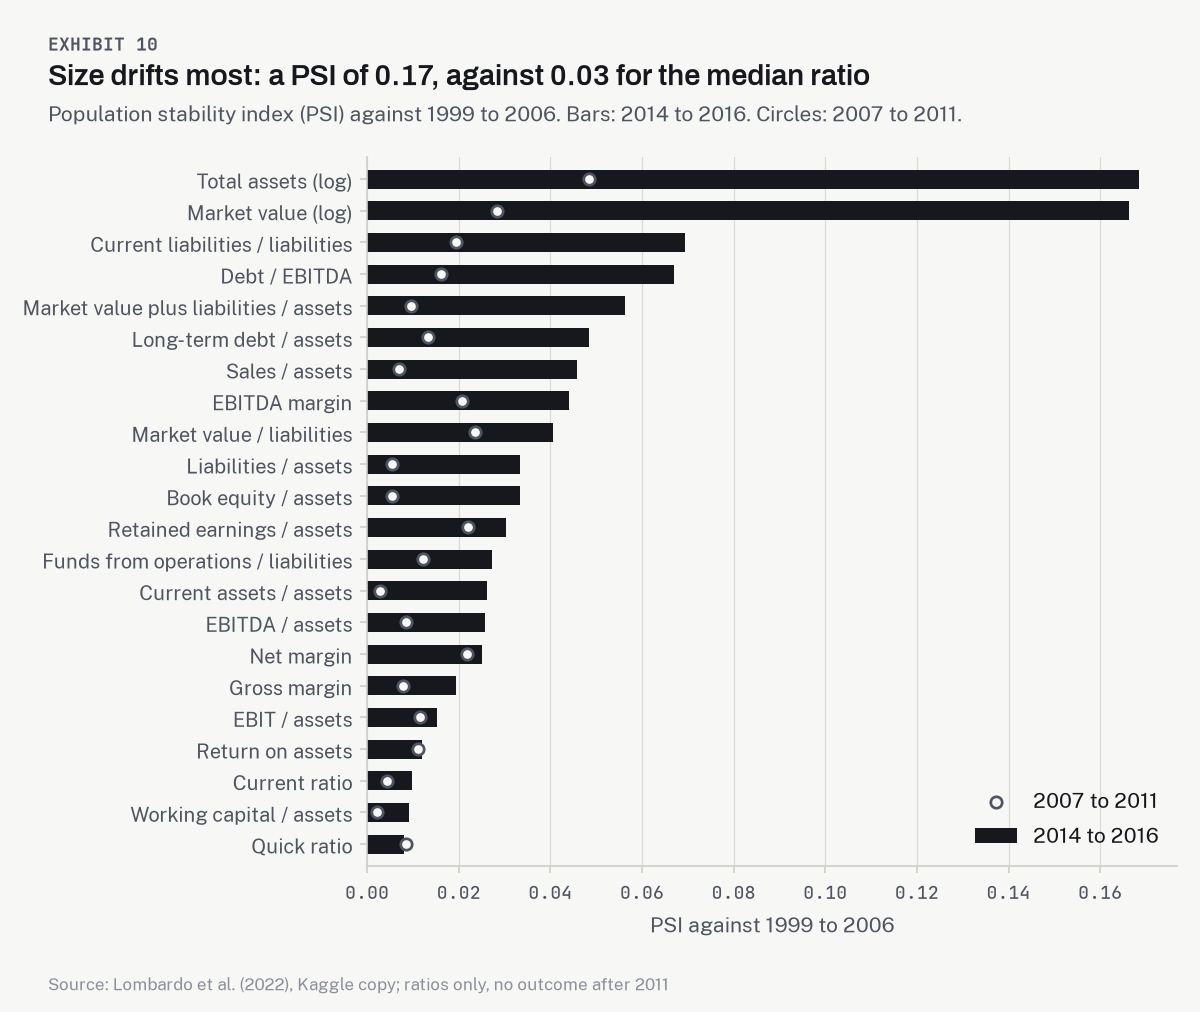

In [24]:
ERAS = {"1999 to 2006": (1999, 2006), "2007 to 2011": (2007, DEV_END), "2014 to 2016": HOLDOUT}
by_era = {name: features.loc[features["year"].between(*years)] for name, years in ERAS.items()}
first, middle, last = by_era.values()

drift = pd.DataFrame(
    {
        "2007 to 2011": {name: psi(first[name], middle[name]) for name in CONTINUOUS},
        "2014 to 2016": {name: psi(first[name], last[name]) for name in CONTINUOUS},
    }
).sort_values("2014 to 2016")
dollar_drift = pd.Series({name: psi(first[name], last[name]) for name in RAW_ITEMS})
# The title and the reading say the two size ratios drift most. Checked here.
assert set(drift.index[-2:]) == set(FAMILIES["size"])

store.put("psi_assets", drift.loc["log_assets", "2014 to 2016"])
store.put("psi_market_cap", drift.loc["log_market_cap", "2014 to 2016"])
store.put("psi_median", drift["2014 to 2016"].median())
store.put("psi_dollar_median", dollar_drift.median())
store.put("psi_longer", int((drift["2014 to 2016"] > drift["2007 to 2011"]).sum()))

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 5.4))
place = np.arange(len(drift))
ax.barh(place, drift["2014 to 2016"], height=0.6, color=viz.INK, label="2014 to 2016")
ax.scatter(drift["2007 to 2011"], place, s=30, facecolor=viz.SHEET, edgecolor=viz.SLATE,
           linewidth=1.3, zorder=3, label="2007 to 2011")  # fmt: skip
ax.set_yticks(place, [viz.label(name) for name in drift.index])
ax.set_ylim(-0.7, len(drift) - 0.3)
ax.grid(axis="y", visible=False)
ax.set_xlabel("PSI against 1999 to 2006")
ax.legend(loc="lower right")
viz.exhibit(
    fig,
    f"Size drifts most: a PSI of {drift['2014 to 2016'].max():.2f}, "
    f"against {drift['2014 to 2016'].median():.2f} for the median ratio",
    "Population stability index (PSI) against 1999 to 2006. Bars: 2014 to 2016. Circles: 2007 to 2011.",
    f"{SOURCE}; ratios only, no outcome after {DEV_END}",
)

**Reading.** In Exhibit 10 the two size ratios stand apart, at 0.168 and 0.166.
The median ratio is at 0.032.

Of the 22 bars, 21 reach past their circle: the drift keeps going the same way as the years pass.

The accounting items drift as size does, with a median index of 0.156.
That is one more reason to model ratios and not amounts.

Q. What does the drift look like in the four ratios that move most?

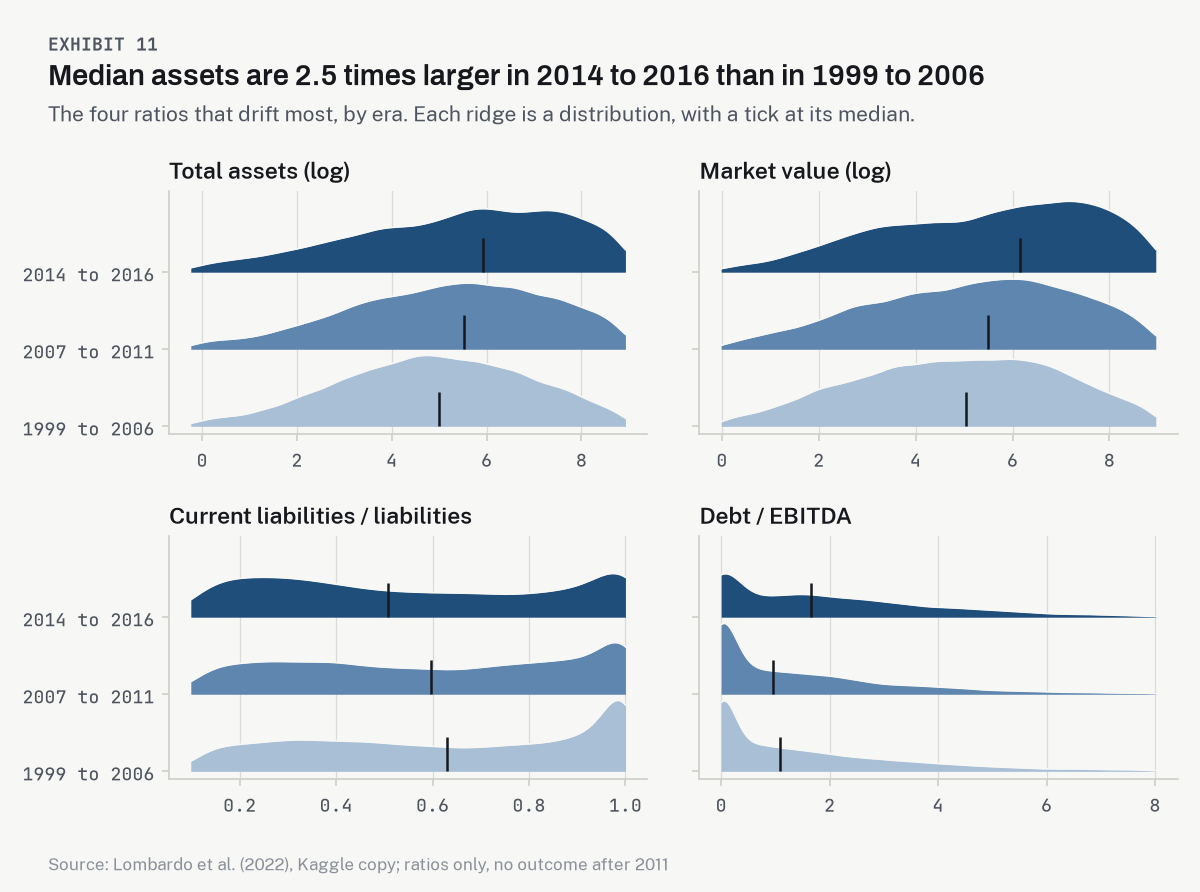

In [25]:
ERA_COLORS = viz.COHORTS  # one hue, light to dark: the eras are in order
moved = list(drift.index[-4:][::-1])

fig, axes = plt.subplots(2, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 4.6), sharey=True)
for ax, name in zip(axes.flat, moved):
    low, high = first[name].quantile([0.02, 0.95])
    grid = np.linspace(low, high, 200)
    framed = {era: rows.loc[rows[name].between(low, high), name] for era, rows in by_era.items()}
    density = {era: gaussian_kde(values)(grid) for era, values in framed.items()}
    tallest = max(curve.max() for curve in density.values())
    for step, (era, color) in enumerate(zip(by_era, ERA_COLORS)):
        ridge = (
            step + 0.92 * density[era] / tallest
        )  # under one step tall, so no ridge hides another
        ax.fill_between(grid, step, ridge, color=color, linewidth=0, zorder=3 - step)
        ax.plot(grid, ridge, color=viz.SHEET, linewidth=0.8, zorder=3 - step)
        ax.vlines(by_era[era][name].median(), step, step + 0.45, color=viz.INK, linewidth=1.2,
                  zorder=4)  # fmt: skip
    ax.set_title(viz.label(name))
    ax.grid(axis="y", visible=False)
axes[0, 0].set_yticks(range(len(by_era)), list(by_era))
axes[0, 0].set_ylim(-0.1, len(by_era) + 0.05)
size_multiple = float(np.exp(last["log_assets"].median() - first["log_assets"].median()))
store.put("size_multiple", size_multiple)
viz.exhibit(
    fig,
    f"Median assets are {size_multiple:.1f} times larger in 2014 to 2016 than in 1999 to 2006",
    "The four ratios that drift most, by era. Each ridge is a distribution, with a tick at its median.",
    f"{SOURCE}; ratios only, no outcome after {DEV_END}",
)

**Reading.** In Exhibit 11 the whole distribution of size slides to the right.
The median company of 2014 to 2016 has 2.5 times the assets of the median company of the first era.

The PSI reads one ratio at a time.
**Adversarial validation** asks about all of them at once: can a model tell which era a row comes from?

Pool the rows of the first era and the last, label each by its era, and fit gradient-boosted trees to the ratios, with companies held out whole as in Chapter 2.
A ROC-AUC of a half says the eras look alike, and one says they share nothing.

**Predict 3.** Guess the score with all 24 ratios.
Then guess how far it falls when the two size ratios are taken away.

Q. Can a model tell the first era from the last?

In [26]:
pooled = pd.concat([first, last])
in_last_era = (pooled["year"] >= HOLDOUT[0]).astype(int)
inputs = {
    "All ratios": RATIOS,
    "Without the two size ratios": [name for name in RATIOS if name not in FAMILIES["size"]],
    "The two size ratios alone": FAMILIES["size"],
}


def era_auc(columns: list[str]) -> float:
    """ROC-AUC of a model that guesses the era of each row from `columns`, companies held out whole."""
    scores = cross_val_predict(
        HistGradientBoostingClassifier(random_state=42),
        pooled[columns],
        in_last_era,
        cv=GroupKFold(5),
        groups=pooled["company_name"],
        method="predict_proba",
    )
    return roc_auc_score(in_last_era, scores[:, 1])


adversarial = pd.Series({name: era_auc(columns) for name, columns in inputs.items()})

store.put("adversarial_all", adversarial["All ratios"])
store.put("adversarial_no_size", adversarial["Without the two size ratios"])
store.put("adversarial_size", adversarial["The two size ratios alone"])

adversarial.round(3).to_frame("ROC-AUC, first era against last")

,"ROC-AUC, first era against last"
All ratios,0.746
Without the two size ratios,0.718
The two size ratios alone,0.630


**Reading.** With every ratio the model scores 0.75, so the two eras are different populations that still overlap a good deal.

Without the size ratios it still scores 0.72, and size alone manages 0.63.
The drift is not one column that could be dropped: it is spread across the accounts in small amounts that a model can add up.

A model fitted on the early years will be asked about companies that look different.
That is why the casebook tests on later years and never on a random sample, and Chapter 4 builds that test.

**Check.** The adversarial model read the ratios of 2014 to 2016. Did that break the seal on those years?

<details>
<summary>Show the answer</summary>

No.
The seal is on outcomes: no label and no failure score is computed on those years before Chapter 7.

Describing the inputs of the test years is allowed, and it is useful.
It says how hard the test will be before it is taken.

</details>

Q. What does the chapter hand on?

In [27]:
FEATURES = feature_names()
# No outcome column is a model input. The label's columns stay in the table for the checks only.
assert not set(FEATURES) & {"status_label", *OUTCOME, "target_1", "target_3"}
assert FEATURES == [*RATIOS, *HISTORY]

features = features.join(industry, on="company_name")
store.save_frame("features", features)
store.put("n_features", len(FEATURES))

pd.Series(
    {
        "rows": len(features),
        "ratios": len(RATIOS),
        "history columns": len(HISTORY),
        "model inputs": len(FEATURES),
        "columns in the table": features.shape[1],
    },
    name="features",
).to_frame()

,features
rows,72393
ratios,24
history columns,21
model inputs,45
columns in the table,73


**Reading.** The table `features` has the 72,393 rows of the labeled panel and 45 model inputs: 24 ratios and 21 history columns.

The outcome columns ride along for the checks.
The library's `feature_names` lists the inputs, so that no outcome column slips into a model.

**The next chapter builds the yardstick: how to tell a good model from a lucky one.**

# Findings

1. No single ratio separates the outcomes: the widest gap between the two distributions is 0.30 (Exhibit 1).
2. Failure shows early: 8 years before its last filing the median failed company has liabilities of 56% of assets, against 49% for the others, and 88% at the end (Exhibit 2).
3. Risk is not spread evenly along a ratio: the most levered fifth fails at 3.6% and the rest at 1.0%, and 4 of the 22 ratios turn (Exhibit 3).
4. Industry is a weak signal: by division the rate runs from 0.8% to 2.5%, with wide intervals (Exhibit 4).
5. A deeper loss is not a higher risk: in the lowest decile of return on assets 1.9% of debt-free firm-years fail, against 3.0% of those with long-term debt (Exhibit 5).
6. Alone, the best ratio has a ROC-AUC of 0.684, and leverage and market value lead (Exhibit 6).
7. The ratios repeat each other inside families: 18 of 22 have their closest neighbor in their own family (Exhibit 7).
8. Leverage and losses together mark the risk: 13% of the rows hold 37% of the positives (Exhibit 8).
9. Levels show early and changes show late: market value falls 44% in the median failed company's last year (Exhibit 9).
10. The ratios drift, size most of all, and a model tells the first era from the last with a ROC-AUC of 0.75 (Exhibit 10, Exhibit 11).

# Your Turn

Three extensions, each with a hint folded under it.

**1. The same companies all the way.** Redraw the leverage panel of Exhibit 2 with only the failed companies that have a row at every step of the path. Does the slide remain?

<details>
<summary>Hint</summary>

Count each company's rows in `paths` with `groupby("company_name")["year"].transform("size")`.
Keep the companies with `YEARS_BACK + 1` rows, then take the median of `liabilities_to_assets` by `years_to_final`.

</details>

**2. A finer cut at the top.** Exhibit 3 puts the top tenth of leverage in one bin. Where inside it does the rate climb fastest?

<details>
<summary>Hint</summary>

Set `BINS = 20` and call `rate_by_bin(dev, "liabilities_to_assets")` again.
Read the last four rows, and compare them with the share of rows whose liabilities are above their assets.

</details>

**3. The history columns, scored alone.** Give the history columns the intervals that Exhibit 6 gives the ratios. Which change beats the level it is built from?

<details>
<summary>Hint</summary>

Call `ranked_alone(dev, HISTORY)`, which takes a minute or two.
Compare `d1_liabilities_to_assets` with the row of `liabilities_to_assets` in `alone`.

</details>

[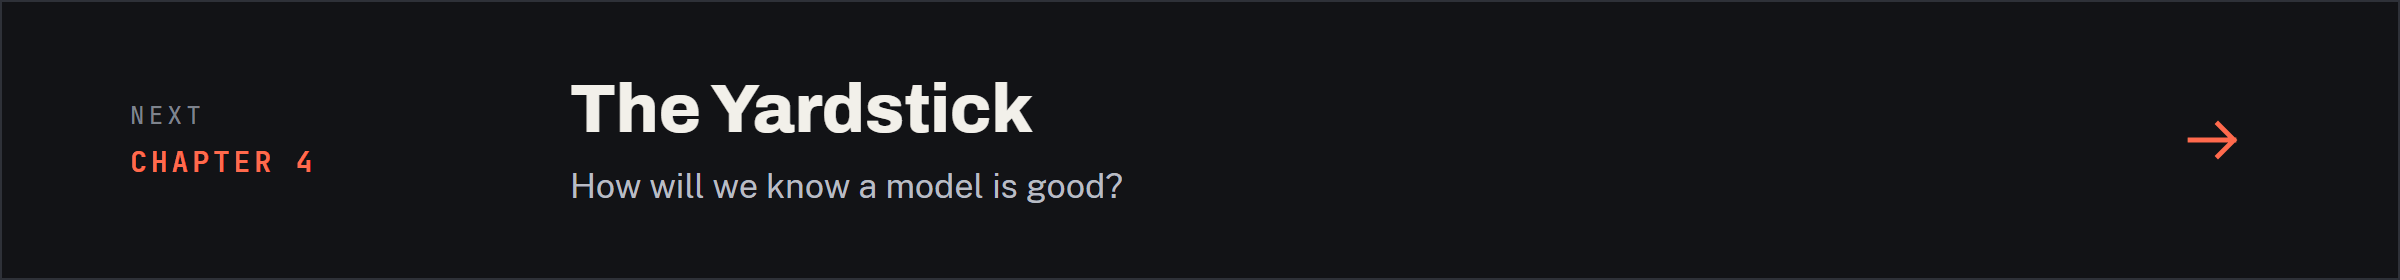](04_the_yardstick.ipynb)